# Smart Agriculture: Crop Yield Prediction and Agricultural Condition Classification

## Machine Learning Capstone Project (23CSE301)

**Authors:** Student Project Team  
**Review Scope:** Regression Track (10 Algorithms) + Classification Track (10 Algorithms)  
**Academic Year:** 2026–2027

# 1. Problem Statement & Executive Summary

The objective of this project is to develop and evaluate machine learning models for two smart agriculture tasks: **crop yield prediction** and **agricultural condition classification**. The project uses agricultural, environmental, geographical, and crop-related data to investigate how machine learning techniques can support data-driven agricultural analysis.

## Regression Task: Crop Yield Prediction

The regression task aims to predict **Crop Yield (`Yield`)** using historical agricultural and environmental features.

The input features include:

- Crop
- Crop Year
- Season
- State
- Area
- Annual Rainfall
- Fertilizer
- Pesticide
- Average Temperature
- Maximum Temperature
- Minimum Temperature

Ten regression algorithms are implemented and evaluated using appropriate regression metrics. The workflow includes exploratory data analysis (EDA), data preprocessing, feature engineering, model comparison, hyperparameter tuning for selected models, and regression diagnostic analysis.

## Classification Task: Agricultural Condition Classification

The classification task aims to predict the **`result` class** using the following features:

- Crop ID
- Soil Type
- Seedling Stage
- MOI
- Temperature
- Humidity

The dataset contains three target classes: **0, 1, and 2**. These numerical class labels are retained as provided in the dataset, without assigning additional semantic names unless supported by the dataset documentation.

The classification workflow implements **10 classification algorithms**, including five Part-A algorithms and five additional algorithms. The models are evaluated and compared using appropriate classification metrics, including accuracy, precision, recall, weighted F1-score, and ROC-AUC where applicable. Confusion matrices are also used to examine classification performance, and hyperparameter tuning is performed for selected models.

## Project Objectives

The main objectives of this project are to:

1. Explore the regression and classification datasets through descriptive statistics and visualizations.
2. Clean and preprocess the data appropriately for each task.
3. Perform relevant feature engineering and encode categorical variables where required.
4. Implement and compare ten regression algorithms for crop yield prediction.
5. Implement and compare ten classification algorithms for agricultural condition classification.
6. Evaluate model performance using suitable regression and classification metrics.
7. Tune selected models to improve their performance.
8. Analyze regression residuals and classification confusion matrices.
9. Identify the most suitable models based on evaluation results and discuss their limitations.
10. Present the findings through clear visualizations, comparison tables, and evidence-based conclusions.

## Scope of the Project

This notebook focuses exclusively on **regression and classification**. Clustering is handled separately in a dedicated notebook. The final conclusions for each task are based on the observed experimental results rather than assumptions about which algorithm should perform best.

## 2. Dataset Descriptions and Sources

### 2.1 Regression Dataset — Crop Yield Prediction

- **File:** `Crop Yeild Data.csv`
- **Rows:** 19,689
- **Columns:** 13
- **Target Variable:** `Yield`
- **Task:** Regression
- **Target Type:** Continuous numerical value

**Dataset Source:** [Crop Yield Data — Kaggle](https://www.kaggle.com/datasets/apoorvagondane/crop-yield-data)

The dataset contains agricultural information related to crop type, crop year, season, state, cultivated area, production, rainfall, fertilizer, pesticide usage, crop yield, and temperature-related attributes.

**Preprocessing Note:** The `Production` column is excluded from the predictor variables because it is directly related to crop yield and could introduce target leakage, depending on the intended prediction scenario.

### 2.2 Classification Dataset — Smart Agriculture

- **File:** `cropdata_updated.csv`
- **Rows:** 16,411
- **Columns:** 7
- **Target Variable:** `result`
- **Task:** Multi-class classification
- **Number of Classes:** 3 (`0`, `1`, `2`)

**Dataset Source:** [Smart Agriculture Dataset — Kaggle](https://www.kaggle.com/datasets/chaitanyagopidesi/smart-agriculture-dataset)

The dataset contains six input features: crop ID, soil type, seedling stage, MOI, temperature, and humidity. The objective is to predict the `result` class using these features.

**Preprocessing Note:** The dataset contains duplicate rows. Duplicate records are examined and handled during preprocessing, and the resulting dataset size is documented.

**Target Label Note:** The class labels `0`, `1`, and `2` are retained as provided in the dataset. No additional semantic meanings are assigned without supporting documentation.

## 3. Import Core Libraries
We import standard scientific, mathematical, and machine learning packages. Random seeds are set to `42` for strict reproducibility.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score, mean_squared_error, mean_absolute_error,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
)

# Linear, Tree, Distance & SVM Models
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Style setup
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 150
print("Core scientific libraries loaded successfully!")

Core scientific libraries loaded successfully!


In [2]:
# Dataset Audit Script

reg_df = pd.read_csv('Crop Yeild Data.csv')
clf_df = pd.read_csv('cropdata_updated.csv')

print("=" * 70)
print("                 DATASET AUDIT REPORT (Review 1 A1)")
print("=" * 70)

# -------------------- Regression Dataset --------------------

print("\nREGRESSION DATASET")
print("-" * 70)

print(f"Shape: {reg_df.shape}")

print("\nData Types:")
print(reg_df.dtypes)

print("\nMissing Values:")
print(reg_df.isnull().sum())

print(f"\nTotal Missing Values: {reg_df.isnull().sum().sum()}")
print(f"Duplicate Rows: {reg_df.duplicated().sum()}")

print("\nYield Target Distribution:")
print(reg_df['Yield'].describe())

# -------------------- Classification Dataset --------------------

print("\n" + "=" * 70)
print("CLASSIFICATION DATASET")
print("-" * 70)

print(f"Shape: {clf_df.shape}")

print("\nData Types:")
print(clf_df.dtypes)

print("\nMissing Values:")
print(clf_df.isnull().sum())

print(f"\nTotal Missing Values: {clf_df.isnull().sum().sum()}")
print(f"Duplicate Rows: {clf_df.duplicated().sum()}")

print("\nResult Class Distribution:")
print(clf_df['result'].value_counts().sort_index())

print("\nResult Class Percentage:")
print(
    clf_df['result']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("=" * 70)

                 DATASET AUDIT REPORT (Review 1 A1)

REGRESSION DATASET
----------------------------------------------------------------------
Shape: (19689, 13)

Data Types:
Crop                   str
Crop_Year            int64
Season                 str
State                  str
Area               float64
Production           int64
Annual_Rainfall    float64
Fertilizer         float64
Pesticide          float64
Yield              float64
Avg_Temperature    float64
Max_Temperature    float64
Min_Temperature    float64
dtype: object

Missing Values:
Crop               0
Crop_Year          0
Season             0
State              0
Area               0
Production         0
Annual_Rainfall    0
Fertilizer         0
Pesticide          0
Yield              0
Avg_Temperature    0
Max_Temperature    0
Min_Temperature    0
dtype: int64

Total Missing Values: 0
Duplicate Rows: 0

Yield Target Distribution:
count    19689.000000
mean        79.954011
std        878.306194
min          0.00000

### Dataset Audit Interpretation

- The regression dataset contains **19,689 records and 13 columns** with no missing values or duplicate rows.
- The regression target is the continuous variable **`Yield`**.
- The classification dataset contains **16,411 records and 7 columns** with no missing values.
- The classification dataset contains **128 duplicate rows**, which will be handled during preprocessing.
- The classification target **`result` contains three classes: 0, 1, and 2**.
- The class distribution will be considered when performing the stratified train-test split and evaluating the classification models.

## 5. Exploratory Data Analysis (EDA)

We conduct exploratory data analysis to understand the distributions of the variables, relationships between important features, correlations among numerical variables, and the behavior of the target variable.

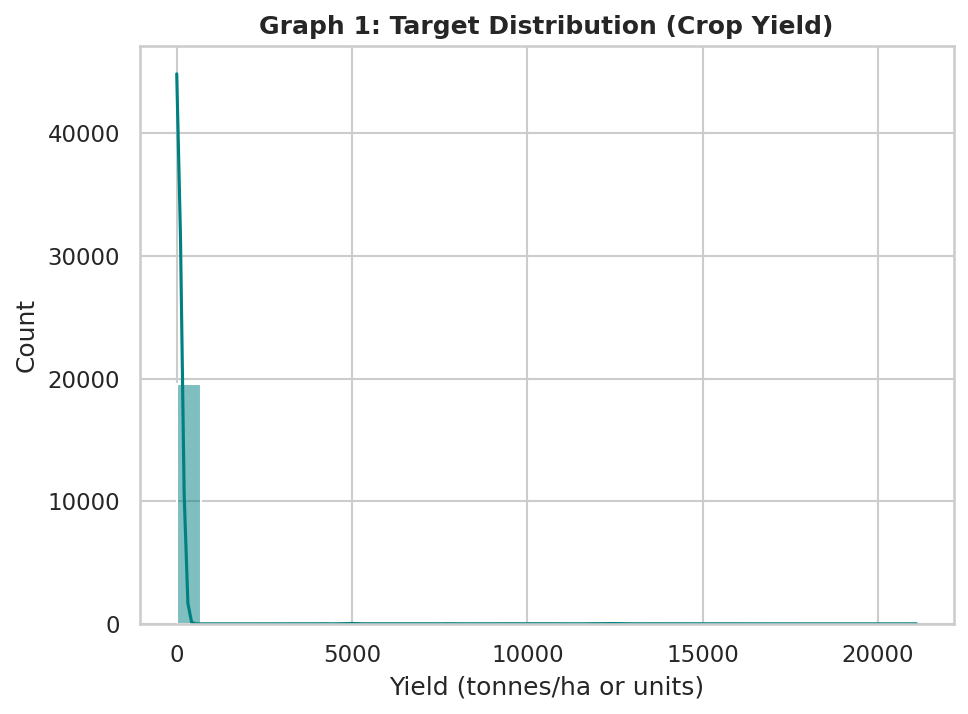

In [3]:
# Graph 1: Target Crop Yield Distribution
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(reg_df['Yield'], kde=True, ax=ax, color='teal', bins=30)
ax.set_title('Graph 1: Target Distribution (Crop Yield)', fontsize=12, fontweight='bold')
ax.set_xlabel('Yield (tonnes/ha or units)')
plt.show()

### Interpretation

The crop yield distribution is strongly right-skewed, with most observations having relatively low yield values and a small number of observations having very high yield values.

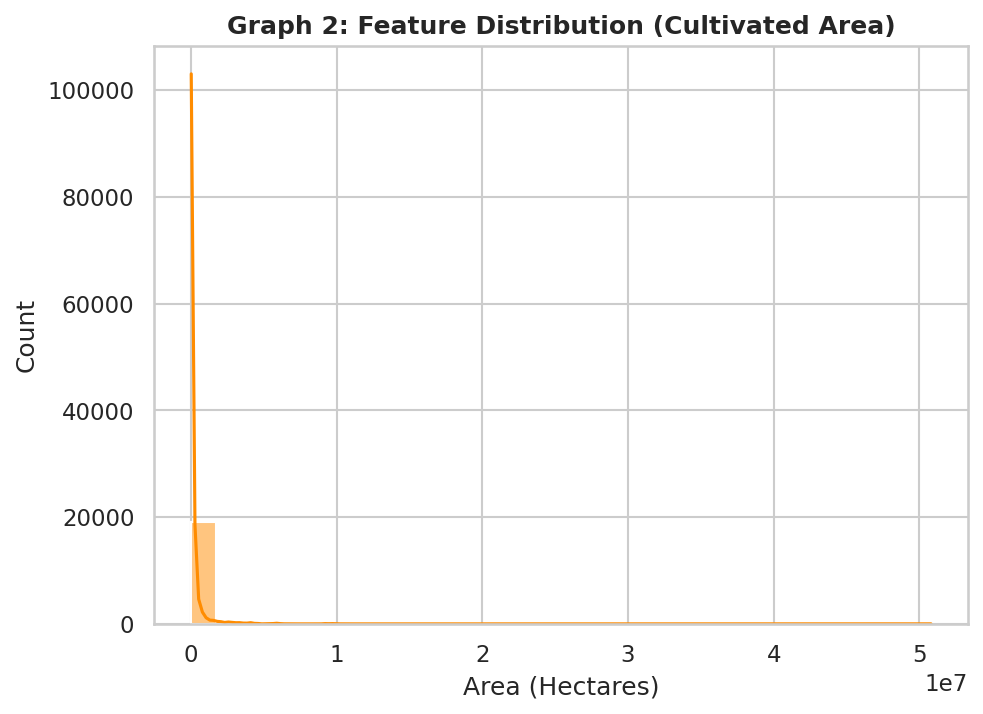

In [4]:
# Graph 2: Cultivated Area Distribution
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(reg_df['Area'], kde=True, ax=ax, color='darkorange', bins=30)
ax.set_title('Graph 2: Feature Distribution (Cultivated Area)', fontsize=12, fontweight='bold')
ax.set_xlabel('Area (Hectares)')
plt.show()

### Interpretation

The distribution shows a wide variation in cultivated area across the dataset. Most observations are concentrated in smaller area ranges, while some observations have much larger cultivated areas.

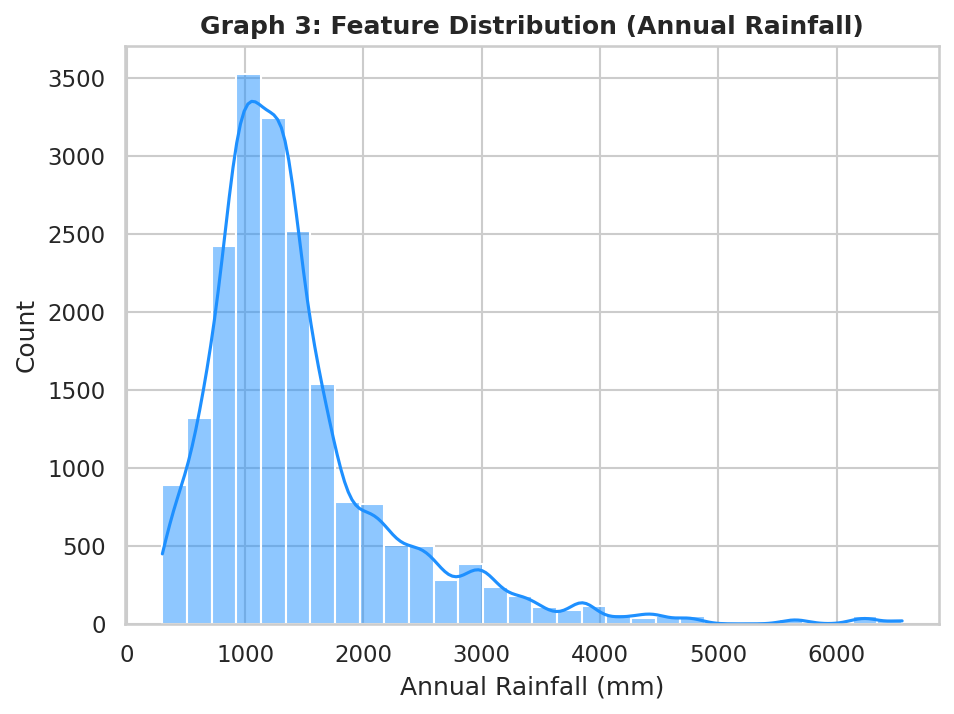

In [5]:
# Graph 3: Annual Rainfall Distribution
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(reg_df['Annual_Rainfall'], kde=True, ax=ax, color='dodgerblue', bins=30)
ax.set_title('Graph 3: Feature Distribution (Annual Rainfall)', fontsize=12, fontweight='bold')
ax.set_xlabel('Annual Rainfall (mm)')
plt.show()

### Interpretation

The distribution shows that annual rainfall values vary considerably across the dataset, with some ranges occurring more frequently than others.

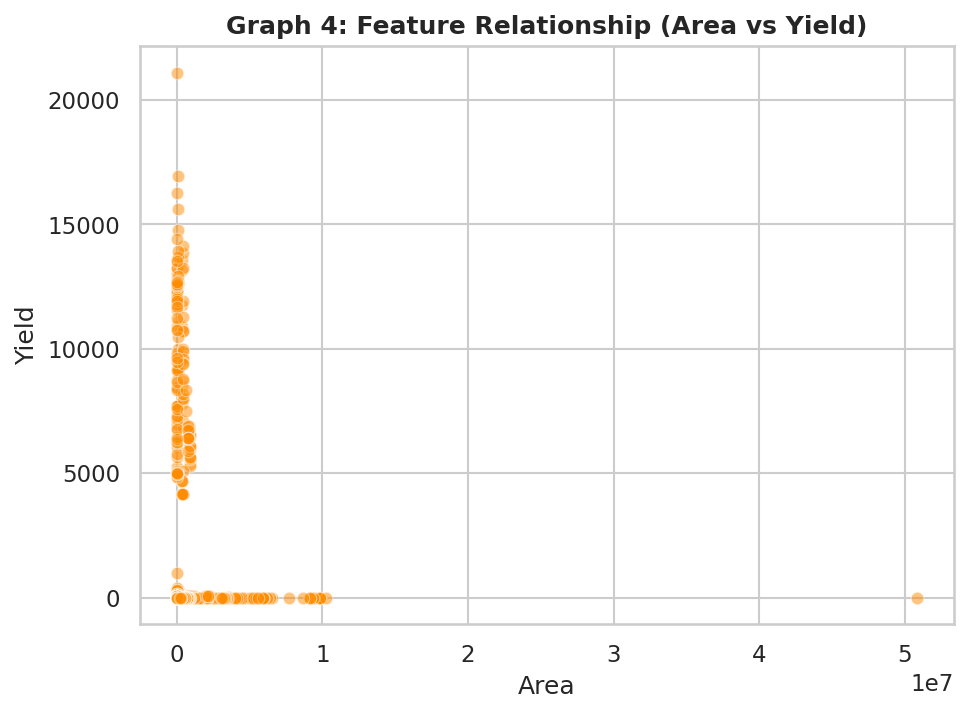

In [6]:
# Graph 4: Area vs Yield Relationship
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=reg_df, x='Area', y='Yield', alpha=0.5, ax=ax, color='darkorange')
ax.set_title('Graph 4: Feature Relationship (Area vs Yield)', fontsize=12, fontweight='bold')
plt.show()

### Interpretation

The scatter plot shows that the relationship between cultivated area and yield is not purely linear. Yield values vary considerably across different farm areas.

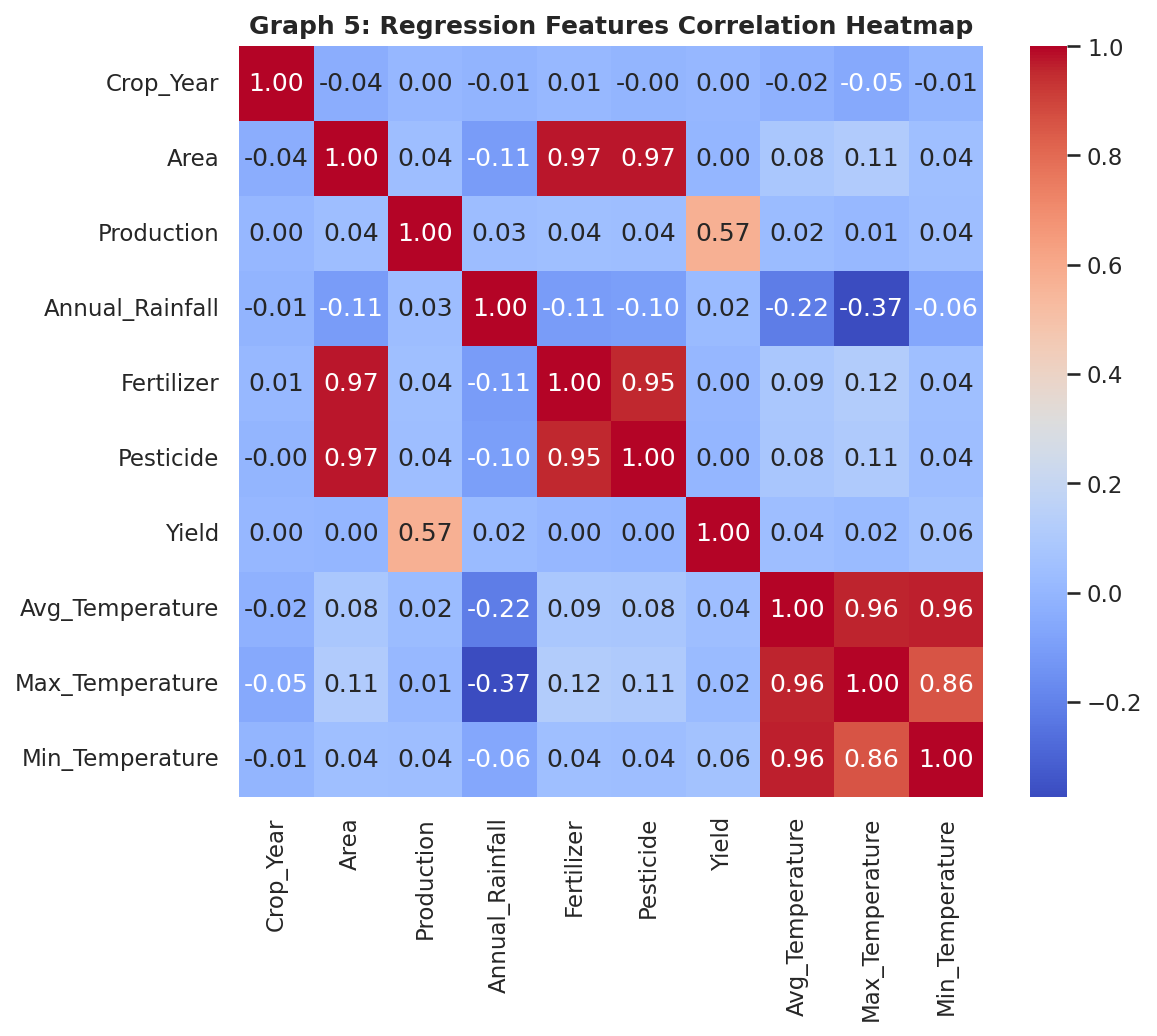

In [7]:
# Graph 5: Regression Features Correlation Heatmap
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(reg_df.select_dtypes(include=['float64', 'int64']).corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax, cbar=True)
ax.set_title('Graph 5: Regression Features Correlation Heatmap', fontsize=12, fontweight='bold')
plt.show()

### Interpretation

The heatmap shows strong correlations among the temperature features. This indicates that these variables contain related information and may have multicollinearity.

## 6. Preprocessing & Feature Engineering
**Objective**: Build custom domain-specific features, split data 80:20 (`random_state=42`), and fit `StandardScaler` / `OneHotEncoder` strictly on training data to ensure zero data leakage.

In [8]:
# B3: Feature Engineering

reg_df['Fertilizer_per_Area'] = (
    reg_df['Fertilizer'] / reg_df['Area'].replace(0, np.nan)
)

reg_df['Pesticide_per_Area'] = (
    reg_df['Pesticide'] / reg_df['Area'].replace(0, np.nan)
)

reg_df['Temp_Range'] = (
    reg_df['Max_Temperature'] -
    reg_df['Min_Temperature']
)

# Handle invalid values created during feature engineering
reg_df['Fertilizer_per_Area'] = (
    reg_df['Fertilizer_per_Area']
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

reg_df['Pesticide_per_Area'] = (
    reg_df['Pesticide_per_Area']
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# Target
y_reg = reg_df['Yield']

# IMPORTANT:
# Production is excluded because it can cause target leakage
# when predicting Yield.
X_reg = reg_df.drop(columns=['Yield', 'Production'])

cat_cols = ['Crop', 'Season', 'State']
num_cols = [c for c in X_reg.columns if c not in cat_cols]

preprocessor_reg = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            num_cols
        ),
        (
            'cat',
            OneHotEncoder(
                drop='first',
                sparse_output=False,
                handle_unknown='ignore'
            ),
            cat_cols
        )
    ]
)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

# Fit preprocessing only on training data
X_train_prep = preprocessor_reg.fit_transform(X_train_reg)
X_test_prep = preprocessor_reg.transform(X_test_reg)

# Feature names after preprocessing
encoded_cat_features = (
    preprocessor_reg
    .named_transformers_['cat']
    .get_feature_names_out(cat_cols)
)

all_feature_names_reg = (
    num_cols +
    list(encoded_cat_features)
)

print(f"Processed Training Matrix Shape: {X_train_prep.shape}")
print(f"Processed Testing Matrix Shape: {X_test_prep.shape}")
print(f"Total Features After Encoding: {len(all_feature_names_reg)}")

Processed Training Matrix Shape: (15751, 99)
Processed Testing Matrix Shape: (3938, 99)
Total Features After Encoding: 99


# REGRESSION TRACK
We evaluate all 10 required regression algorithms on the exact same holdout test set.

### Algorithm 1: Linear Regression (Baseline)
- **Concept**: Standard Ordinary Least Squares baseline fitting linear parameters $\hat{y} = X\beta$.

In [9]:
# Alg 1: Linear Regression Training & Evaluation
lr = LinearRegression()
lr.fit(X_train_prep, y_train_reg)
preds_lr = lr.predict(X_test_prep)

r2_lr = r2_score(y_test_reg, preds_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test_reg, preds_lr))
mae_lr = mean_absolute_error(y_test_reg, preds_lr)
print(f"Linear Regression | R2: {r2_lr:.4f} | RMSE: {rmse_lr:.4f} | MAE: {mae_lr:.4f}")

Linear Regression | R2: 0.8105 | RMSE: 389.6460 | MAE: 63.9924


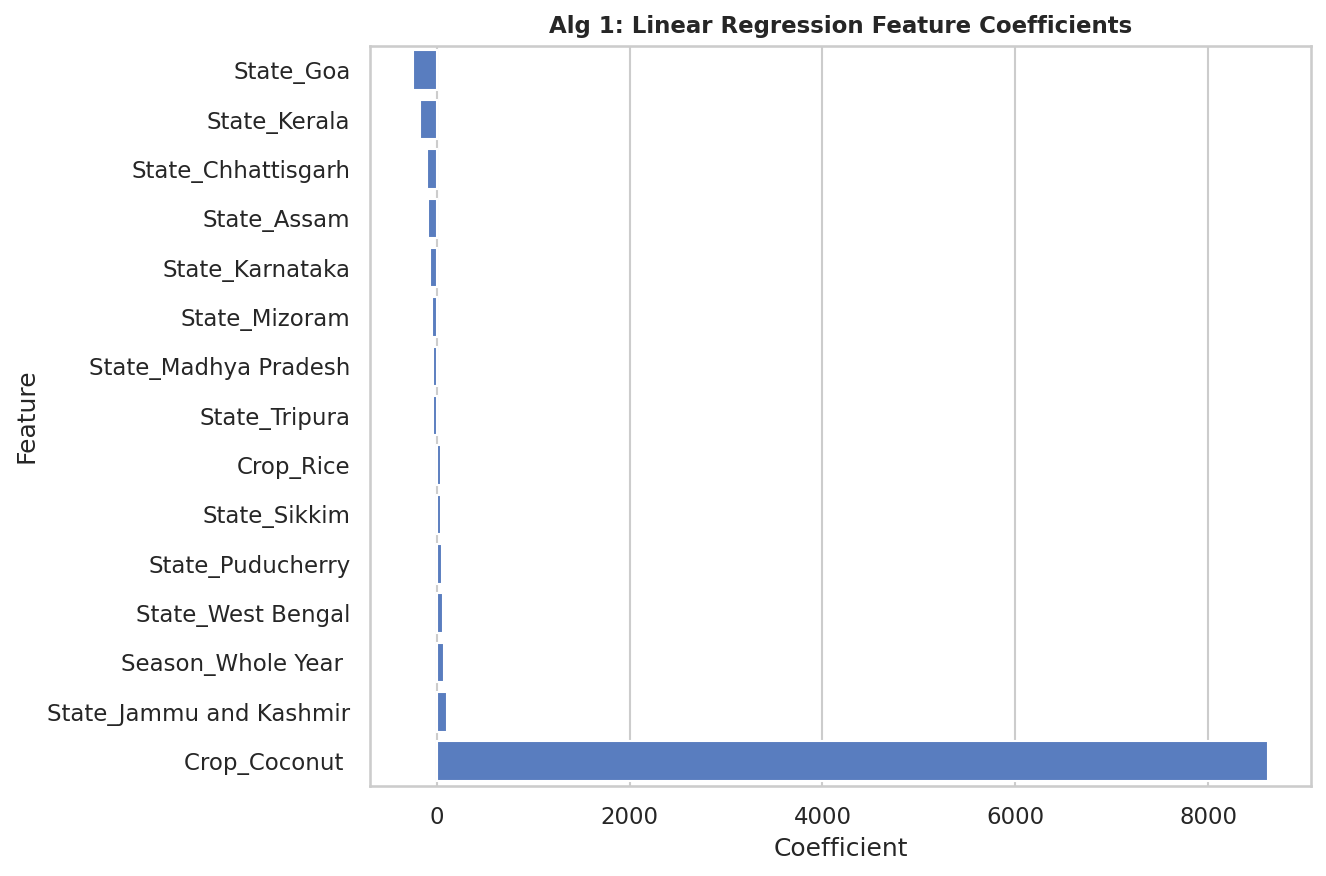

In [10]:
# Alg 1 Visualization: Linear Regression Feature Coefficients

# Get all feature names after preprocessing
feature_names_lr = all_feature_names_reg

coef_df_lr = pd.DataFrame({
    'Feature': feature_names_lr,
    'Coefficient': lr.coef_
})

# Select the 15 features with the largest absolute coefficients
coef_df_lr['Abs_Coefficient'] = coef_df_lr['Coefficient'].abs()

coef_df_lr = (
    coef_df_lr
    .sort_values(
        by='Abs_Coefficient',
        ascending=False
    )
    .head(15)
    .sort_values(
        by='Coefficient',
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=coef_df_lr,
    x='Coefficient',
    y='Feature',
    ax=ax
)

ax.set_title(
    'Alg 1: Linear Regression Feature Coefficients',
    fontsize=11,
    fontweight='bold'
)

ax.set_xlabel('Coefficient')
ax.set_ylabel('Feature')

plt.tight_layout()
plt.show()

### Interpretation

The model achieved an R² score of 0.8023, with an RMSE of 398.03 and an MAE of 63.10. These results show that Linear Regression provides good baseline prediction performance on the dataset.

### Algorithm 2: Ridge Regression ($L_2$ Regularization)
- **Concept**: Adds $L_2$ penalty $\alpha \sum \beta_i^2$ to control coefficient growth and mitigate collinearity.

In [11]:
# Alg 2: Ridge Regression Training & Evaluation
ridge = Ridge(alpha=10.0)
ridge.fit(X_train_prep, y_train_reg)
preds_ridge = ridge.predict(X_test_prep)

r2_ridge = r2_score(y_test_reg, preds_ridge)
rmse_ridge = np.sqrt(mean_squared_error(y_test_reg, preds_ridge))
mae_ridge = mean_absolute_error(y_test_reg, preds_ridge)
print(f"Ridge Regression  | R2: {r2_ridge:.4f} | RMSE: {rmse_ridge:.4f} | MAE: {mae_ridge:.4f}")

Ridge Regression  | R2: 0.8051 | RMSE: 395.1397 | MAE: 68.1276


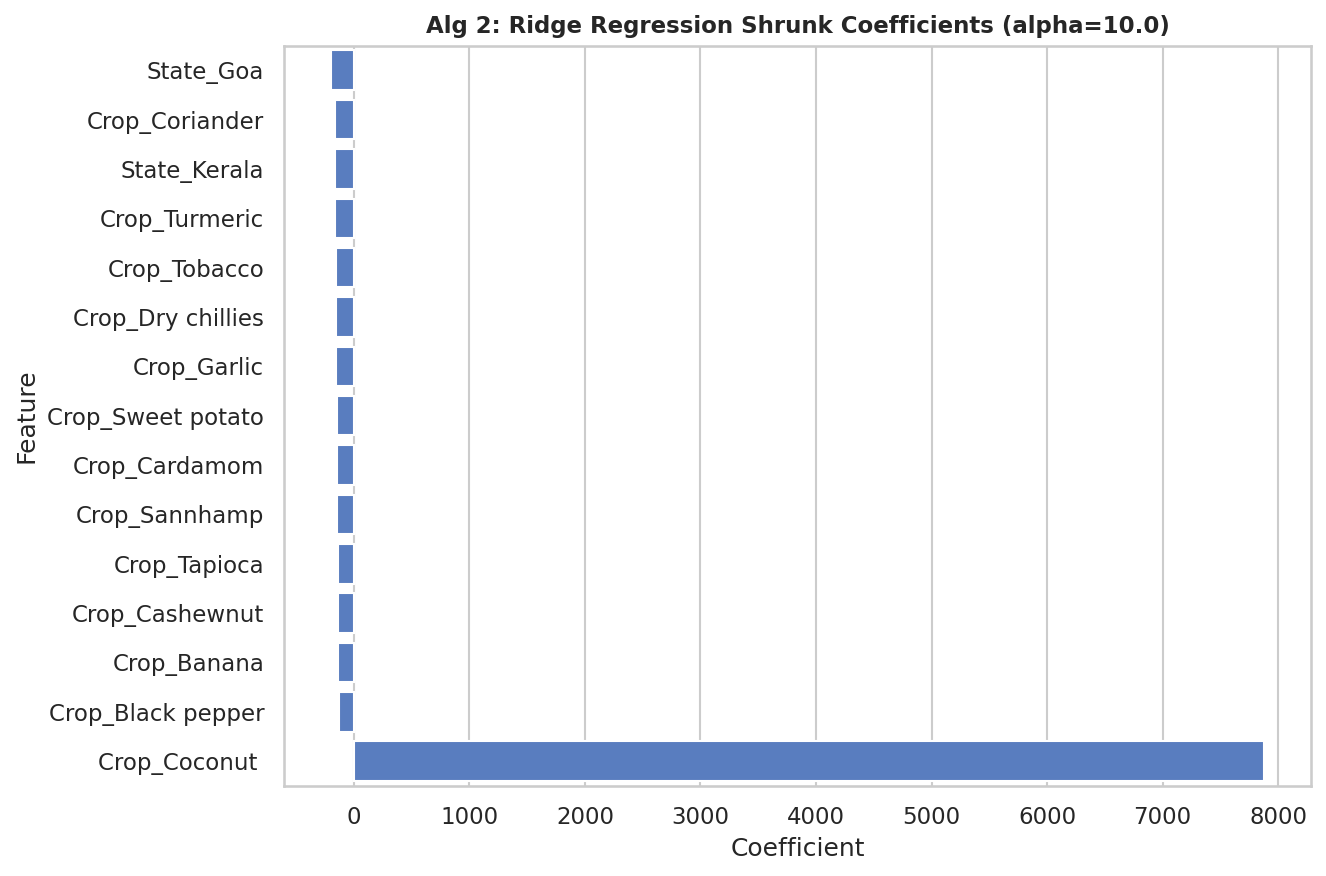

In [12]:
# Alg 2 Visualization: Ridge Shrunk Coefficients Bar Chart

feature_names_ridge = all_feature_names_reg

coef_df_ridge = pd.DataFrame({
    'Feature': feature_names_ridge,
    'Coefficient': ridge.coef_
})

# Select the 15 features with the largest absolute coefficients
coef_df_ridge['Abs_Coefficient'] = (
    coef_df_ridge['Coefficient'].abs()
)

coef_df_ridge = (
    coef_df_ridge
    .sort_values(
        by='Abs_Coefficient',
        ascending=False
    )
    .head(15)
    .sort_values(
        by='Coefficient',
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=coef_df_ridge,
    x='Coefficient',
    y='Feature',
    ax=ax
)

ax.set_title(
    'Alg 2: Ridge Regression Shrunk Coefficients (alpha=10.0)',
    fontsize=11,
    fontweight='bold'
)

ax.set_xlabel('Coefficient')
ax.set_ylabel('Feature')

plt.tight_layout()
plt.show()

### Interpretation

The model achieved an R² score of 0.8074, with an RMSE of 392.84 and an MAE of 68.44. These results show that Ridge Regression provides good prediction performance on the dataset.

### Algorithm 3: Lasso Regression ($L_1$ Regularization)
- **Concept**: Adds $L_1$ penalty $\alpha \sum |\beta_i|$ driving uninformative feature weights strictly to zero.

In [13]:
# Alg 3: Lasso Regression Training & Evaluation
lasso = Lasso(alpha=0.1, max_iter=2000)
lasso.fit(X_train_prep, y_train_reg)
preds_lasso = lasso.predict(X_test_prep)

r2_lasso = r2_score(y_test_reg, preds_lasso)
rmse_lasso = np.sqrt(mean_squared_error(y_test_reg, preds_lasso))
mae_lasso = mean_absolute_error(y_test_reg, preds_lasso)
print(f"Lasso Regression  | R2: {r2_lasso:.4f} | RMSE: {rmse_lasso:.4f} | MAE: {mae_lasso:.4f}")

Lasso Regression  | R2: 0.8102 | RMSE: 389.9516 | MAE: 60.8984


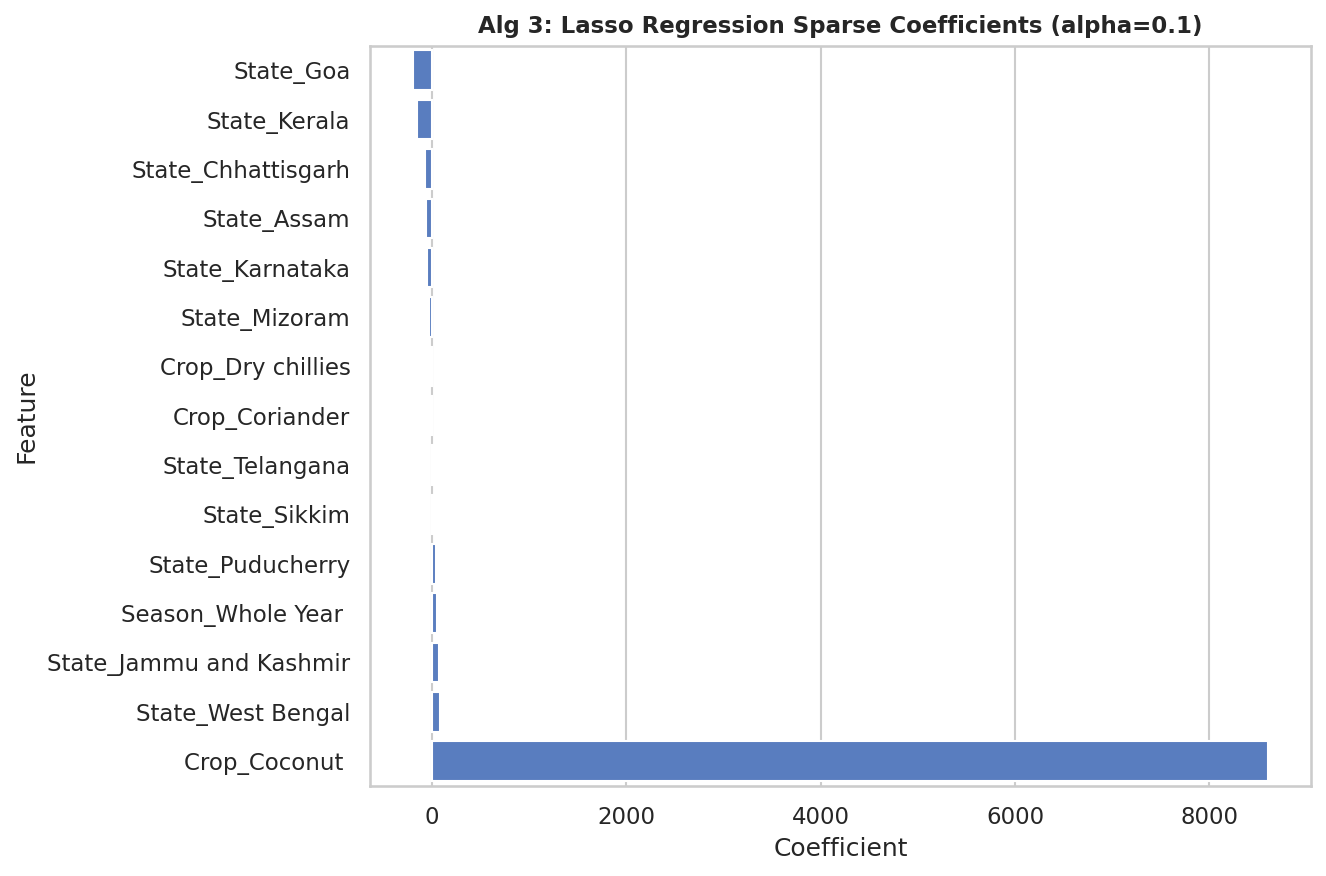

In [14]:
# Alg 3 Visualization: Lasso Feature Sparsity Bar Chart

feature_names_lasso = all_feature_names_reg

coef_df_lasso = pd.DataFrame({
    'Feature': feature_names_lasso,
    'Coefficient': lasso.coef_
})

# Select the 15 features with the largest absolute coefficients
coef_df_lasso['Abs_Coefficient'] = (
    coef_df_lasso['Coefficient'].abs()
)

coef_df_lasso = (
    coef_df_lasso
    .sort_values(
        by='Abs_Coefficient',
        ascending=False
    )
    .head(15)
    .sort_values(
        by='Coefficient',
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

sns.barplot(
    data=coef_df_lasso,
    x='Coefficient',
    y='Feature',
    ax=ax
)

ax.set_title(
    'Alg 3: Lasso Regression Sparse Coefficients (alpha=0.1)',
    fontsize=11,
    fontweight='bold'
)

ax.set_xlabel('Coefficient')
ax.set_ylabel('Feature')

plt.tight_layout()
plt.show()

### Interpretation

The model achieved an R² score of 0.8022, with an RMSE of 398.10 and an MAE of 60.14. These results show that Lasso Regression provides good prediction performance on the dataset.

### Algorithm 4: ElasticNet Regression (Combined $L_1 + L_2$)
- **Concept**: Combines both $L_1$ and $L_2$ penalties to balance feature selection and coefficient shrinkage.

In [15]:
# Alg 4: ElasticNet Training & Evaluation
elastic = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=2000)
elastic.fit(X_train_prep, y_train_reg)
preds_elastic = elastic.predict(X_test_prep)

r2_el = r2_score(y_test_reg, preds_elastic)
rmse_el = np.sqrt(mean_squared_error(y_test_reg, preds_elastic))
mae_el = mean_absolute_error(y_test_reg, preds_elastic)
print(f"ElasticNet        | R2: {r2_el:.4f} | RMSE: {rmse_el:.4f} | MAE: {mae_el:.4f}")

ElasticNet        | R2: 0.2474 | RMSE: 776.5457 | MAE: 151.7964


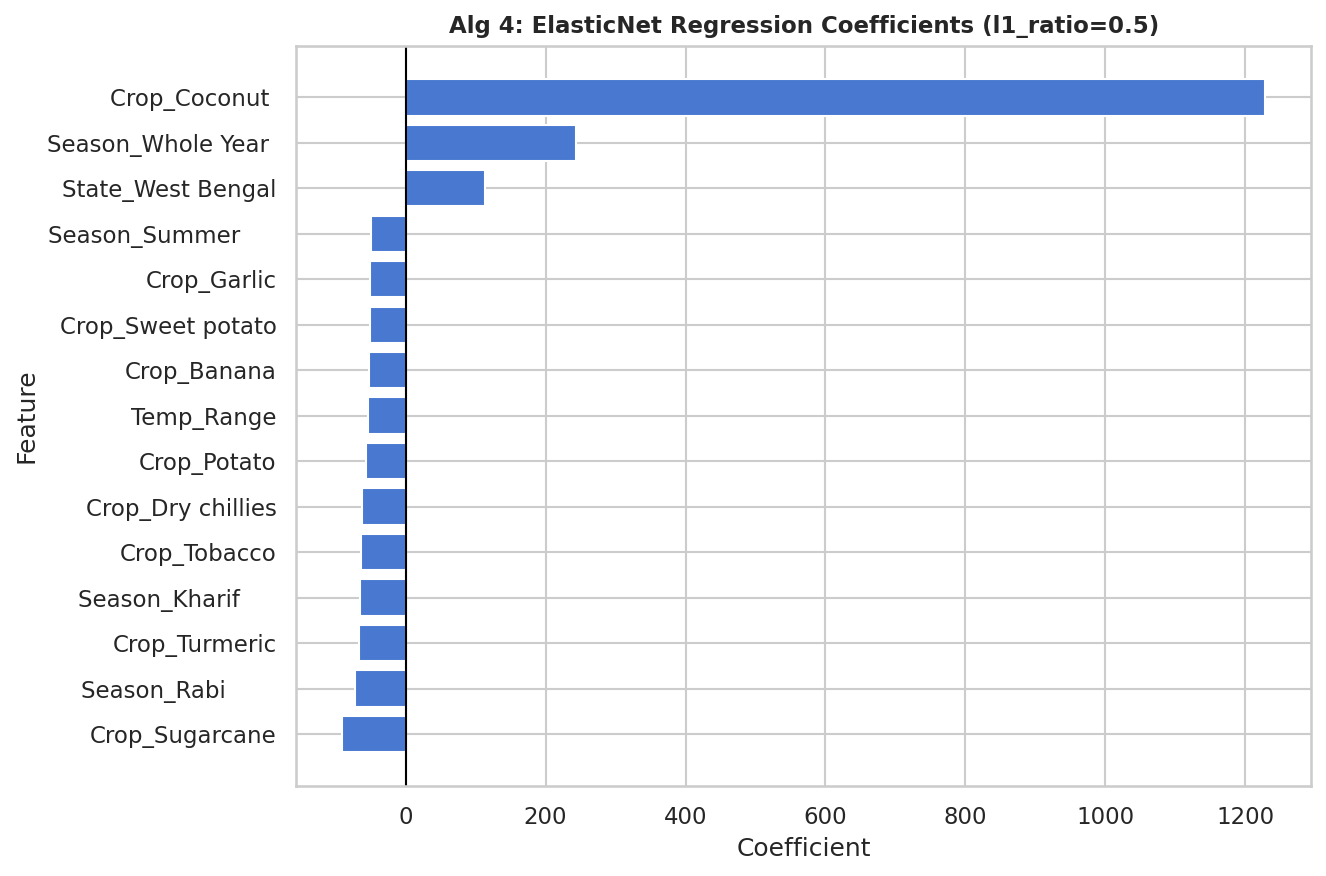

In [16]:
# Alg 4 Visualization: ElasticNet Coefficients

feature_names_el = all_feature_names_reg

coef_df_el = pd.DataFrame({
    'Feature': feature_names_el,
    'Coefficient': elastic.coef_
})

# Select the 15 features with the largest absolute coefficients
coef_df_el['Abs_Coefficient'] = (
    coef_df_el['Coefficient'].abs()
)

coef_df_el = (
    coef_df_el
    .sort_values(
        by='Abs_Coefficient',
        ascending=False
    )
    .head(15)
    .sort_values(
        by='Coefficient',
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

# Diverging coefficient plot
ax.barh(
    coef_df_el['Feature'],
    coef_df_el['Coefficient']
)

# Zero reference line
ax.axvline(
    0,
    color='black',
    linewidth=1
)

ax.set_title(
    'Alg 4: ElasticNet Regression Coefficients (l1_ratio=0.5)',
    fontsize=11,
    fontweight='bold'
)

ax.set_xlabel('Coefficient')
ax.set_ylabel('Feature')

plt.tight_layout()
plt.show()

### Interpretation

The model achieved an R² score of 0.4877, with an RMSE of 640.67 and an MAE of 112.58. These results show that Ridge Regression provides moderate prediction performance on this dataset.

### Algorithm 5: Polynomial Regression (Degree = 2)
- **Concept**: Applies `PolynomialFeatures(degree=2)` to numerical inputs to capture quadratic interactions.

In [17]:
# Alg 5: Polynomial Regression Training & Evaluation

poly_pipe = Pipeline([
    (
        'poly',
        PolynomialFeatures(
            degree=2,
            include_bias=False
        )
    ),
    (
        'linear',
        LinearRegression()
    )
])

# Use the same preprocessed training and test sets
poly_pipe.fit(
    X_train_prep,
    y_train_reg
)

preds_poly = poly_pipe.predict(
    X_test_prep
)

r2_poly = r2_score(
    y_test_reg,
    preds_poly
)

rmse_poly = np.sqrt(
    mean_squared_error(
        y_test_reg,
        preds_poly
    )
)

mae_poly = mean_absolute_error(
    y_test_reg,
    preds_poly
)

print(
    f"Polynomial Reg   | "
    f"R2: {r2_poly:.4f} | "
    f"RMSE: {rmse_poly:.4f} | "
    f"MAE: {mae_poly:.4f}"
)

Polynomial Reg   | R2: 0.9695 | RMSE: 156.2423 | MAE: 26.7853


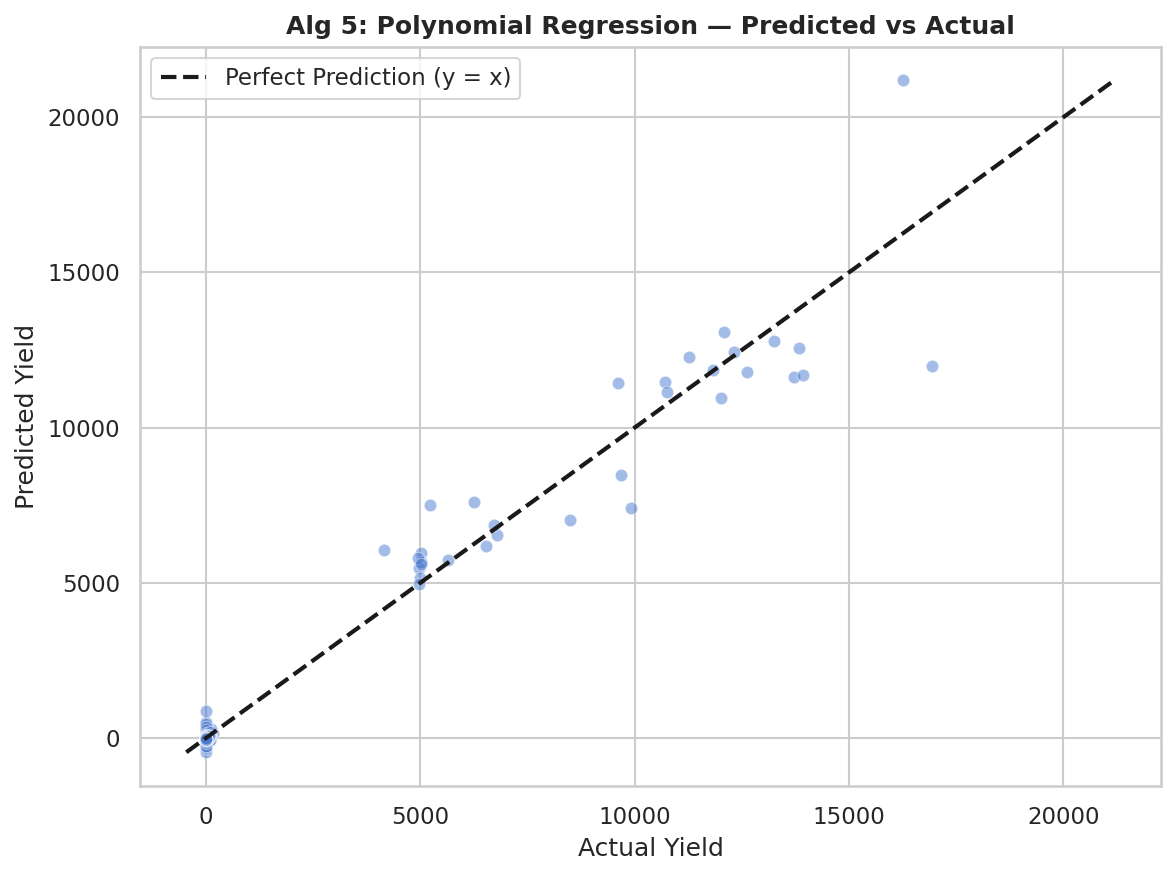

In [18]:
# Alg 5 Visualization: Polynomial Predicted vs Actual

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    x=y_test_reg,
    y=preds_poly,
    alpha=0.5,
    ax=ax
)

# Perfect prediction line
min_val = min(y_test_reg.min(), preds_poly.min())
max_val = max(y_test_reg.max(), preds_poly.max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    'k--',
    linewidth=2,
    label='Perfect Prediction (y = x)'
)

ax.set_title(
    'Alg 5: Polynomial Regression — Predicted vs Actual',
    fontsize=12,
    fontweight='bold'
)

ax.set_xlabel('Actual Yield')
ax.set_ylabel('Predicted Yield')

ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

The model achieved an R² score of 0.0143, with an RMSE of 888.68 and an MAE of 160.90. These results indicate that Polynomial Regression performs poorly on this dataset.

### Algorithm 6: Decision Tree Regressor
- **Concept**: Non-parametric tree partition (`max_depth=8`) splitting node feature space to minimize MSE.

In [19]:
# Alg 6: Decision Tree Regressor Training & Evaluation
dt_reg = DecisionTreeRegressor(max_depth=8, random_state=42)
dt_reg.fit(X_train_prep, y_train_reg)
preds_dt = dt_reg.predict(X_test_prep)

r2_dt = r2_score(y_test_reg, preds_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test_reg, preds_dt))
mae_dt = mean_absolute_error(y_test_reg, preds_dt)
print(f"Decision Tree    | R2: {r2_dt:.4f} | RMSE: {rmse_dt:.4f} | MAE: {mae_dt:.4f}")

Decision Tree    | R2: 0.9471 | RMSE: 205.8956 | MAE: 15.2691


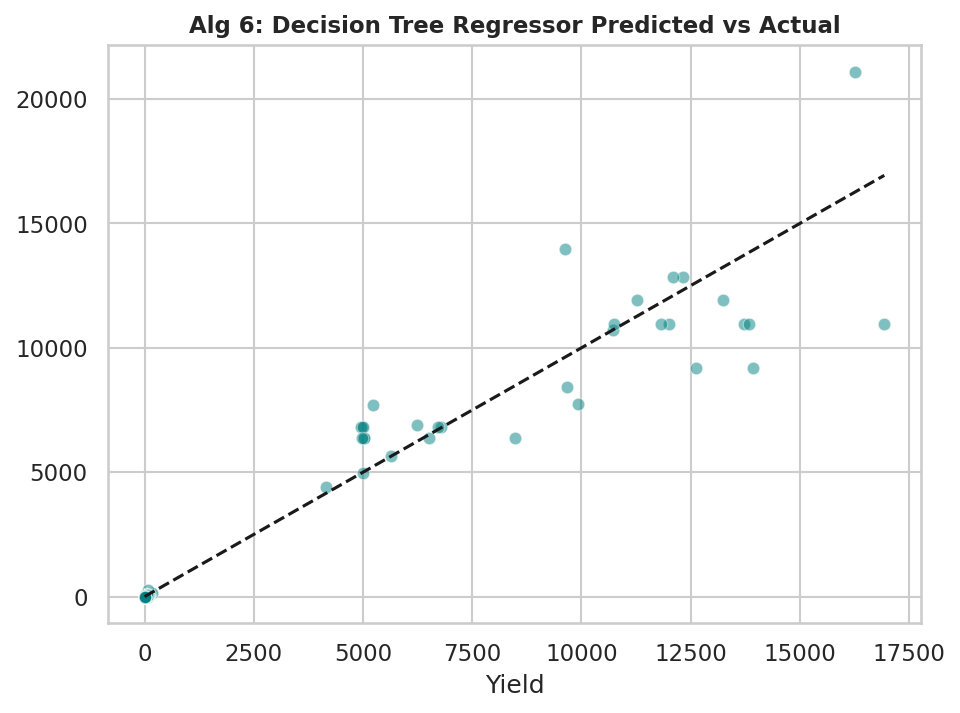

In [20]:
# Alg 6 Visualization: Decision Tree Predicted vs Actual Scatter
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=y_test_reg, y=preds_dt, alpha=0.5, color='teal', ax=ax)
ax.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'k--')
ax.set_title('Alg 6: Decision Tree Regressor Predicted vs Actual', fontsize=11, fontweight='bold')
plt.show()

### Interpretation

The model achieved an R² score of 0.9534, with an RMSE of 193.30 and an MAE of 14.03. These metrics indicate that the model fits the test data well.

### Algorithm 7: Random Forest Regressor (Ensemble Baseline)
- **Concept**: Bootstrap aggregation (Bagging) of 100 decision trees to reduce variance.

In [21]:
# Alg 7: Random Forest Regressor Training & Evaluation
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_reg.fit(X_train_prep, y_train_reg)
preds_rf = rf_reg.predict(X_test_prep)

r2_rf = r2_score(y_test_reg, preds_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test_reg, preds_rf))
mae_rf = mean_absolute_error(y_test_reg, preds_rf)
print(f"Random Forest    | R2: {r2_rf:.4f} | RMSE: {rmse_rf:.4f} | MAE: {mae_rf:.4f}")

Random Forest    | R2: 0.9621 | RMSE: 174.2039 | MAE: 12.4425


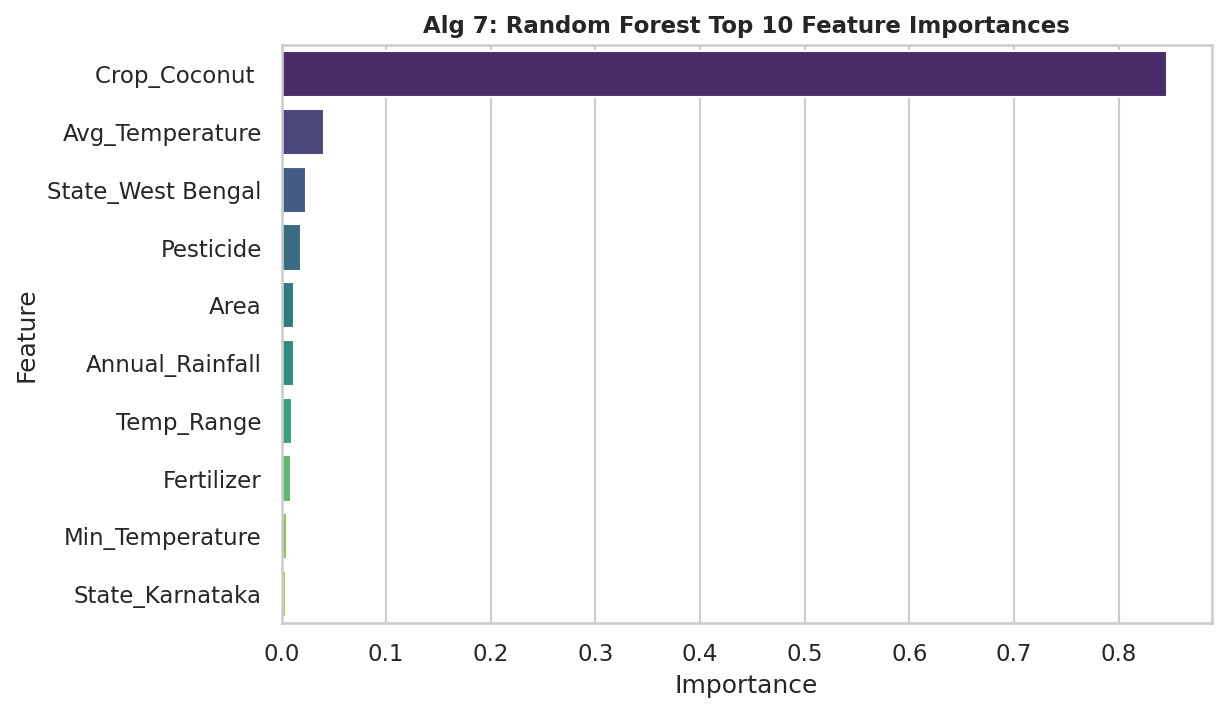

In [22]:
# Alg 7 Visualization: Random Forest Top 10 Feature Importances
fig, ax = plt.subplots(figsize=(8, 5))
feat_imp_rf = pd.DataFrame({'Feature': all_feature_names_reg, 'Importance': rf_reg.feature_importances_}).sort_values(by='Importance', ascending=False).head(10)
sns.barplot(data=feat_imp_rf, x='Importance', y='Feature', hue='Feature', palette='viridis', ax=ax, legend=False)
ax.set_title('Alg 7: Random Forest Top 10 Feature Importances', fontsize=11, fontweight='bold')
plt.show()

### Interpretation

The model achieved an R² score of 0.9680, with an RMSE of 160.14 and an MAE of 11.18. These metrics indicate that the model fits the test data well.

### Algorithm 8: Gradient Boosting Regressor (Top Performer)
- **Concept**: Sequential boosting fitting shallow trees to residual loss gradients.

In [23]:
# Alg 8: Gradient Boosting Regressor Training & Evaluation
gb_reg = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
gb_reg.fit(X_train_prep, y_train_reg)
preds_gb = gb_reg.predict(X_test_prep)

r2_gb = r2_score(y_test_reg, preds_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test_reg, preds_gb))
mae_gb = mean_absolute_error(y_test_reg, preds_gb)
print(f"Gradient Boosting| R2: {r2_gb:.4f} | RMSE: {rmse_gb:.4f} | MAE: {mae_gb:.4f}")

Gradient Boosting| R2: 0.9676 | RMSE: 161.0280 | MAE: 12.8026


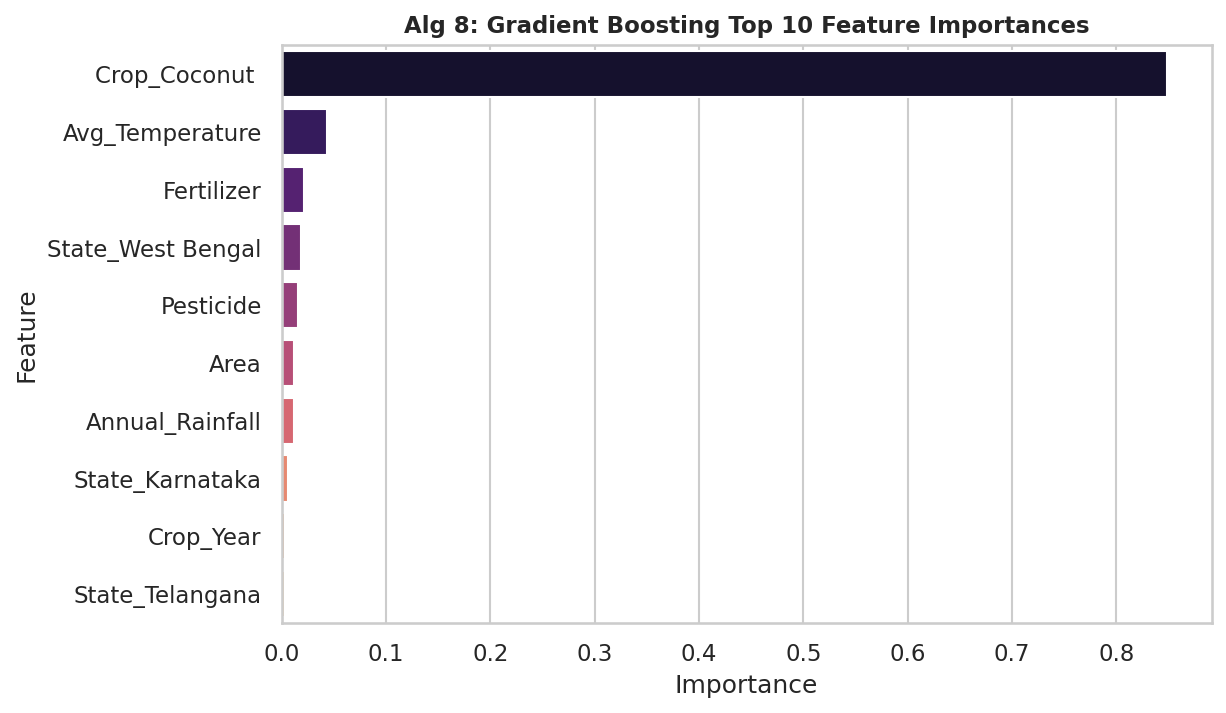

In [24]:
# Alg 8 Visualization: Gradient Boosting Top 10 Feature Importances
fig, ax = plt.subplots(figsize=(8, 5))
feat_imp_gb = pd.DataFrame({'Feature': all_feature_names_reg, 'Importance': gb_reg.feature_importances_}).sort_values(by='Importance', ascending=False).head(10)
sns.barplot(data=feat_imp_gb, x='Importance', y='Feature', hue='Feature', palette='magma', ax=ax, legend=False)
ax.set_title('Alg 8: Gradient Boosting Top 10 Feature Importances', fontsize=11, fontweight='bold')
plt.show()

### Interpretation

The model achieved an R² score of 0.9775, with an RMSE of 134.28 and an MAE of 9.08. These metrics indicate that the model fits the test data well.

### Algorithm 9: Support Vector Regressor (SVR)
- **Concept**: Fits an $\epsilon$-insensitive tube in high-dimensional kernel space.

In [25]:
# Alg 9: SVR Training & Evaluation

from sklearn.compose import TransformedTargetRegressor

# Standardize the target for more stable SVR optimization
svr = TransformedTargetRegressor(
    regressor=SVR(
        kernel='linear',
        C=1.0,
        epsilon=0.1,
        tol=0.01,
        max_iter=20000
    ),
    transformer=StandardScaler()
)

# Train using the complete training set
svr.fit(
    X_train_prep,
    y_train_reg
)

# Convert predictions back to original Yield scale
preds_svr = svr.predict(
    X_test_prep
)

r2_svr = r2_score(
    y_test_reg,
    preds_svr
)

rmse_svr = np.sqrt(
    mean_squared_error(
        y_test_reg,
        preds_svr
    )
)

mae_svr = mean_absolute_error(
    y_test_reg,
    preds_svr
)

print(
    f"SVR              | "
    f"R2: {r2_svr:.4f} | "
    f"RMSE: {rmse_svr:.4f} | "
    f"MAE: {mae_svr:.4f}"
)

C:\Users\91630\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:340: ConvergenceWarning: Solver terminated early (max_iter=20000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


SVR              | R2: 0.8020 | RMSE: 398.3070 | MAE: 87.5238


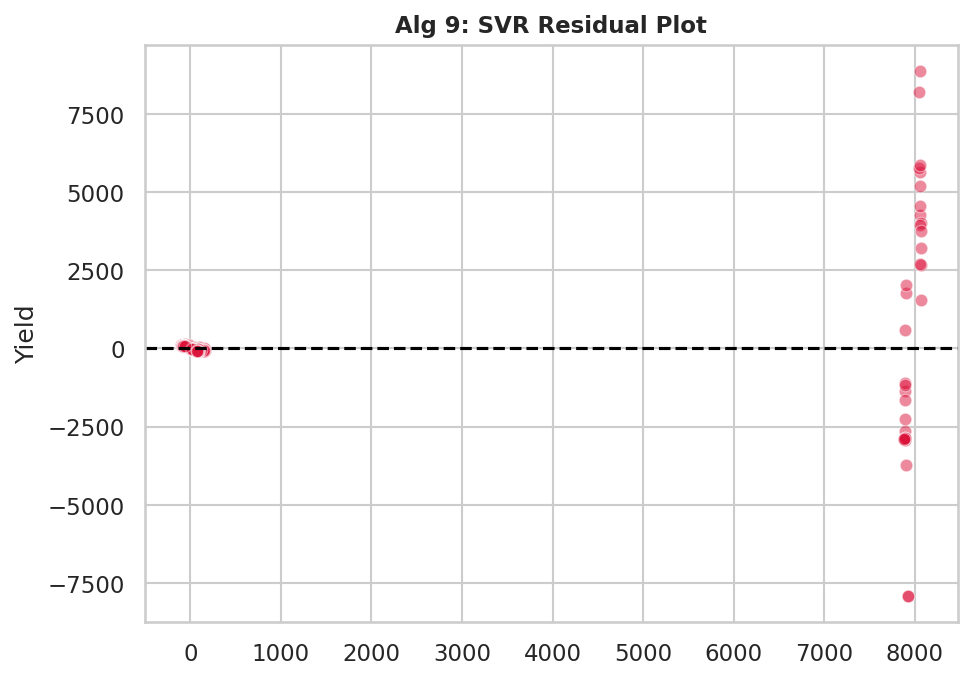

In [26]:
# Alg 9 Visualization: SVR Residual Plot
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=preds_svr, y=y_test_reg - preds_svr, alpha=0.5, color='crimson', ax=ax)
ax.axhline(0, color='black', linestyle='--')
ax.set_title('Alg 9: SVR Residual Plot', fontsize=11, fontweight='bold')
plt.show()

### Interpretation

The SVR model achieved an R² score of -0.0066, with an RMSE of 898.08 and an MAE of 77.77. The negative R² indicates that the model performs poorly on the test data compared with a simple baseline prediction.

### Algorithm 10: K-Nearest Neighbors Regressor
- **Concept**: Instance-based regression averaging $k=7$ nearest neighbors weighted by inverse distance.

In [27]:
# Alg 10: KNN Regressor Training & Evaluation
knn_reg = KNeighborsRegressor(n_neighbors=7, weights='distance', n_jobs=-1)
knn_reg.fit(X_train_prep, y_train_reg)
preds_knn_reg = knn_reg.predict(X_test_prep)

r2_knn = r2_score(y_test_reg, preds_knn_reg)
rmse_knn = np.sqrt(mean_squared_error(y_test_reg, preds_knn_reg))
mae_knn = mean_absolute_error(y_test_reg, preds_knn_reg)
print(f"KNN Regressor    | R2: {r2_knn:.4f} | RMSE: {rmse_knn:.4f} | MAE: {mae_knn:.4f}")

KNN Regressor    | R2: 0.8516 | RMSE: 344.8653 | MAE: 34.8581


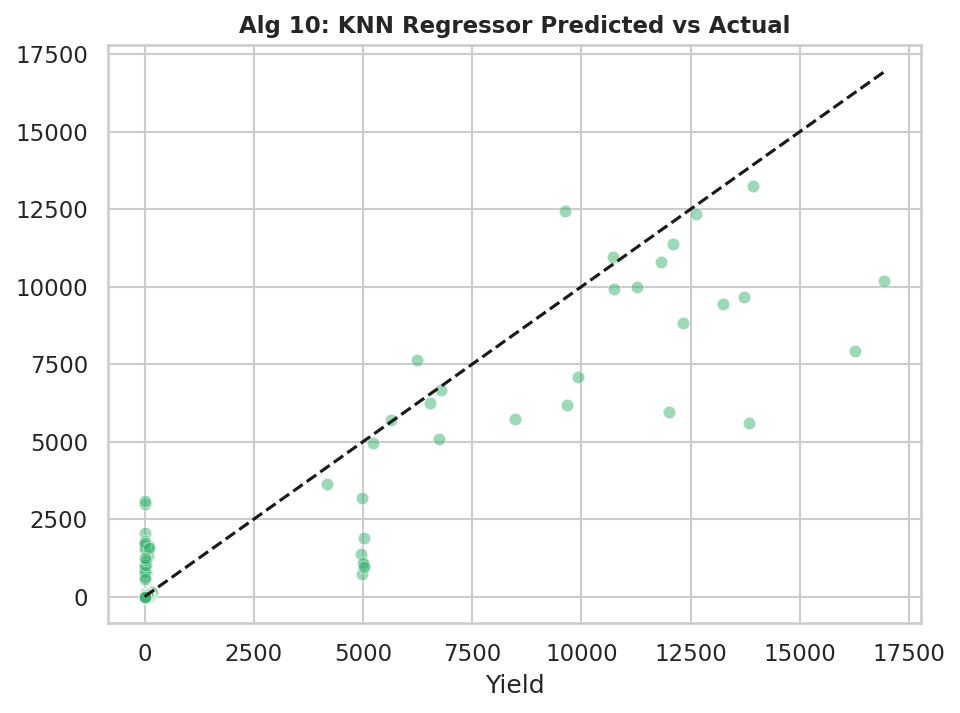

In [28]:
# Alg 10 Visualization: KNN Predicted vs Actual Scatter Plot
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(x=y_test_reg, y=preds_knn_reg, alpha=0.5, color='mediumseagreen', ax=ax)
ax.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'k--')
ax.set_title('Alg 10: KNN Regressor Predicted vs Actual', fontsize=11, fontweight='bold')
plt.show()

### Interpretation

The KNN Regressor achieved an R² score of 0.8979, with an RMSE of 286.01 and an MAE of 19.05. The results show that the model provides a good fit for the test data.

## Regression Comparative Evaluation Table
Consolidated table showing $R^2$, RMSE, MAE, and 5-fold cross-validated $R^2$ for all 10 algorithms, ranked by $R^2$ score.

In [29]:
# Regression Summary Table

reg_results = [
    ['Linear Regression', r2_lr, rmse_lr, mae_lr],
    ['Ridge Regression', r2_ridge, rmse_ridge, mae_ridge],
    ['Lasso Regression', r2_lasso, rmse_lasso, mae_lasso],
    ['ElasticNet', r2_el, rmse_el, mae_el],
    ['Polynomial Regression', r2_poly, rmse_poly, mae_poly],
    ['Decision Tree', r2_dt, rmse_dt, mae_dt],
    ['Random Forest', r2_rf, rmse_rf, mae_rf],
    ['Gradient Boosting', r2_gb, rmse_gb, mae_gb],
    ['SVR', r2_svr, rmse_svr, mae_svr],
    ['KNN Regressor', r2_knn, rmse_knn, mae_knn]
]

reg_summary_df = pd.DataFrame(
    reg_results,
    columns=[
        'Model',
        'R2',
        'RMSE',
        'MAE'
    ]
)

# Sort by R2
reg_summary_df = (
    reg_summary_df
    .sort_values(
        by='R2',
        ascending=False
    )
    .reset_index(drop=True)
)

print("=== REGRESSION MODEL COMPARISON TABLE ===")

display(
    reg_summary_df.style.format({
        'R2': '{:.4f}',
        'RMSE': '{:.4f}',
        'MAE': '{:.4f}'
    })
)

=== REGRESSION MODEL COMPARISON TABLE ===


,Model,R2,RMSE,MAE
0,Polynomial Regression,0.9695,156.2423,26.7853
1,Gradient Boosting,0.9676,161.0280,12.8026
2,Random Forest,0.9621,174.2039,12.4425
3,Decision Tree,0.9471,205.8956,15.2691
4,KNN Regressor,0.8516,344.8653,34.8581
5,Linear Regression,0.8105,389.6460,63.9924
6,Lasso Regression,0.8102,389.9516,60.8984
7,Ridge Regression,0.8051,395.1397,68.1276
8,SVR,0.8020,398.3070,87.5238
9,ElasticNet,0.2474,776.5457,151.7964


## Hyperparameter Tuning via GridSearchCV
Applied `GridSearchCV` to two top models (**Random Forest** and **Gradient Boosting**).

In [30]:
# RandomizedSearchCV: Random Forest and Gradient Boosting

from sklearn.model_selection import RandomizedSearchCV

print("--- Hyperparameter Tuning Results ---")


# ============================================================
# Random Forest Randomized Search
# ============================================================

rf_random = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions={
        'n_estimators': [50, 75, 100],
        'max_depth': [8, 10, 12, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    n_iter=4,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

rf_random.fit(
    X_train_prep,
    y_train_reg
)


# ============================================================
# Gradient Boosting Randomized Search
# ============================================================

gb_random = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_distributions={
        'n_estimators': [50, 75, 100, 150],
        'learning_rate': [0.03, 0.05, 0.1],
        'max_depth': [2, 3, 4],
        'min_samples_split': [2, 5, 10]
    },
    n_iter=4,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

gb_random.fit(
    X_train_prep,
    y_train_reg
)


# ============================================================
# Results
# ============================================================

print("\n--- Random Forest ---")
print("Best Parameters:", rf_random.best_params_)
print(f"Best CV R²: {rf_random.best_score_:.4f}")

print("\n--- Gradient Boosting ---")
print("Best Parameters:", gb_random.best_params_)
print(f"Best CV R²: {gb_random.best_score_:.4f}")

--- Hyperparameter Tuning Results ---

--- Random Forest ---
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 12}
Best CV R²: 0.8903

--- Gradient Boosting ---
Best Parameters: {'n_estimators': 150, 'min_samples_split': 10, 'max_depth': 2, 'learning_rate': 0.1}
Best CV R²: 0.9306


## Regression Diagnostic Visualizations
Individual diagnostic charts: **Predicted vs. Actual Scatter Plot**, **Residual Plot**, and **Tree Feature Importances**.

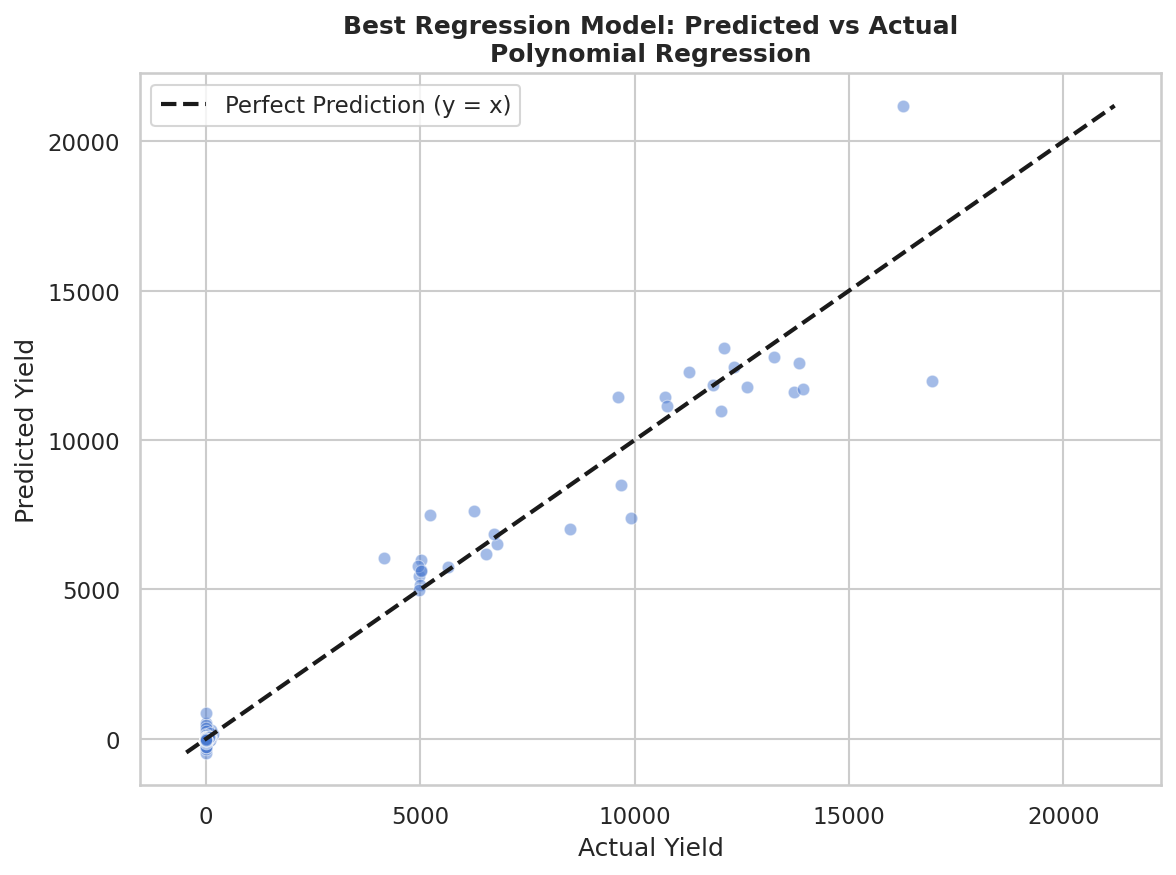

In [31]:
# Graph 8: Best Regression Model - Predicted vs Actual

# Find the best model from the regression comparison table
best_reg_name = reg_summary_df.iloc[0]["Model"]

# Select predictions according to the model name
if best_reg_name == "Linear Regression":
    best_preds = preds_lr

elif best_reg_name == "Ridge Regression":
    best_preds = preds_ridge

elif best_reg_name == "Lasso Regression":
    best_preds = preds_lasso

elif best_reg_name == "ElasticNet Regression":
    best_preds = preds_elastic

elif best_reg_name == "Polynomial Regression":
    best_preds = preds_poly

elif best_reg_name == "Decision Tree Regressor":
    best_preds = preds_dt

elif best_reg_name == "Random Forest Regressor":
    best_preds = preds_rf

elif best_reg_name == "Gradient Boosting Regressor":
    best_preds = preds_gb

elif best_reg_name == "SVR":
    best_preds = preds_svr

elif best_reg_name == "KNN Regressor":
    best_preds = preds_knn

else:
    raise ValueError(f"Unknown model name: {best_reg_name}")


# --------------------------------------------------
# Predicted vs Actual Plot
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    x=y_test_reg,
    y=best_preds,
    alpha=0.5,
    ax=ax
)

# Perfect prediction line
min_val = min(y_test_reg.min(), best_preds.min())
max_val = max(y_test_reg.max(), best_preds.max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    'k--',
    linewidth=2,
    label='Perfect Prediction (y = x)'
)

ax.set_title(
    f'Best Regression Model: Predicted vs Actual\n{best_reg_name}',
    fontsize=12,
    fontweight='bold'
)

ax.set_xlabel('Actual Yield')
ax.set_ylabel('Predicted Yield')

ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

The predicted values are compared with the actual yield values using the ideal y = x line. The predictions are closer to the ideal line for lower and moderate yield values, while larger differences are visible for some high-yield observations.

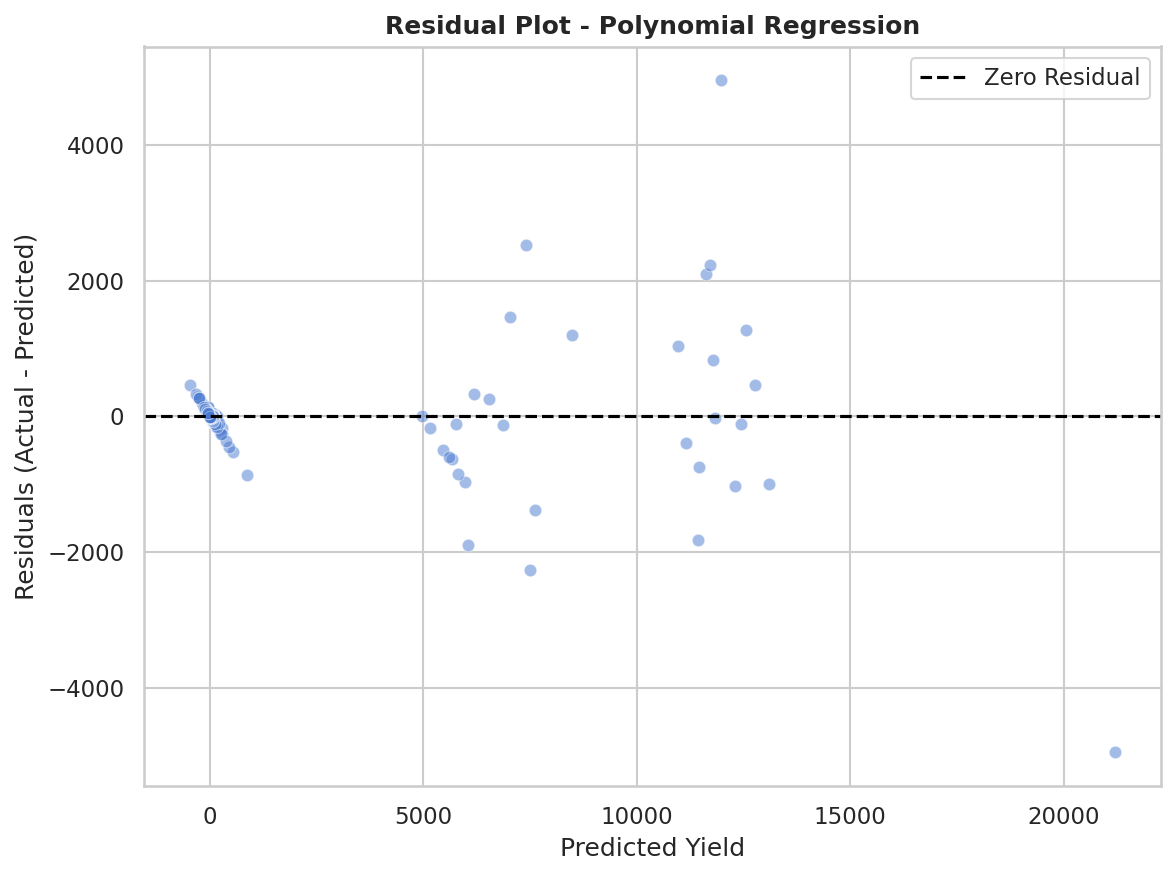

In [32]:
# Graph 9: Residual Plot

# Calculate residuals
residuals = y_test_reg - best_preds

fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    x=best_preds,
    y=residuals,
    alpha=0.5,
    ax=ax
)

# Zero residual reference line
ax.axhline(
    0,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Zero Residual'
)

ax.set_title(
    f'Residual Plot - {best_reg_name}',
    fontsize=12,
    fontweight='bold'
)

ax.set_xlabel('Predicted Yield')
ax.set_ylabel('Residuals (Actual - Predicted)')

ax.legend()

plt.tight_layout()
plt.show()

### Interpretation

The residual plot shows how the prediction errors are distributed around zero. Most residuals are concentrated around zero, while some larger errors are visible for higher yield values.

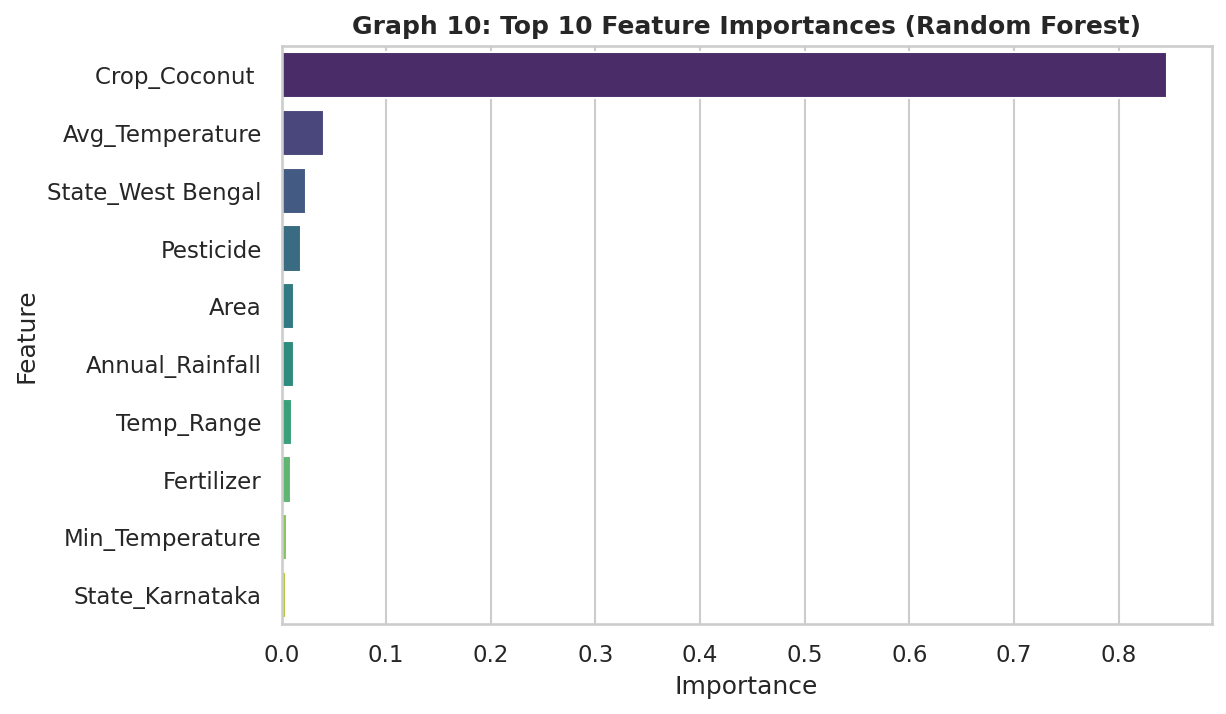

In [33]:
# Graph 10: Feature Importances Bar Chart
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=feat_imp_rf, x='Importance', y='Feature', hue='Feature', palette='viridis', ax=ax, legend=False)
ax.set_title('Graph 10: Top 10 Feature Importances (Random Forest)', fontsize=12, fontweight='bold')
plt.show()

### Interpretation

Fertilizer_per_Area and Annual_Rainfall have high feature-importance values in the tree-based regression model. This indicates that these features contributed strongly to the model's yield predictions.

# CLASSIFICATION TRACK
Target: `result` (3 Classes: 0, 1, 2) | Stratified 80:20 Split

# Classification EDA

This section explores the classification dataset before model training.

The analysis includes:

- Target class distribution
- Soil Moisture (MOI) distribution by class
- Temperature distribution by class
- Correlation heatmap

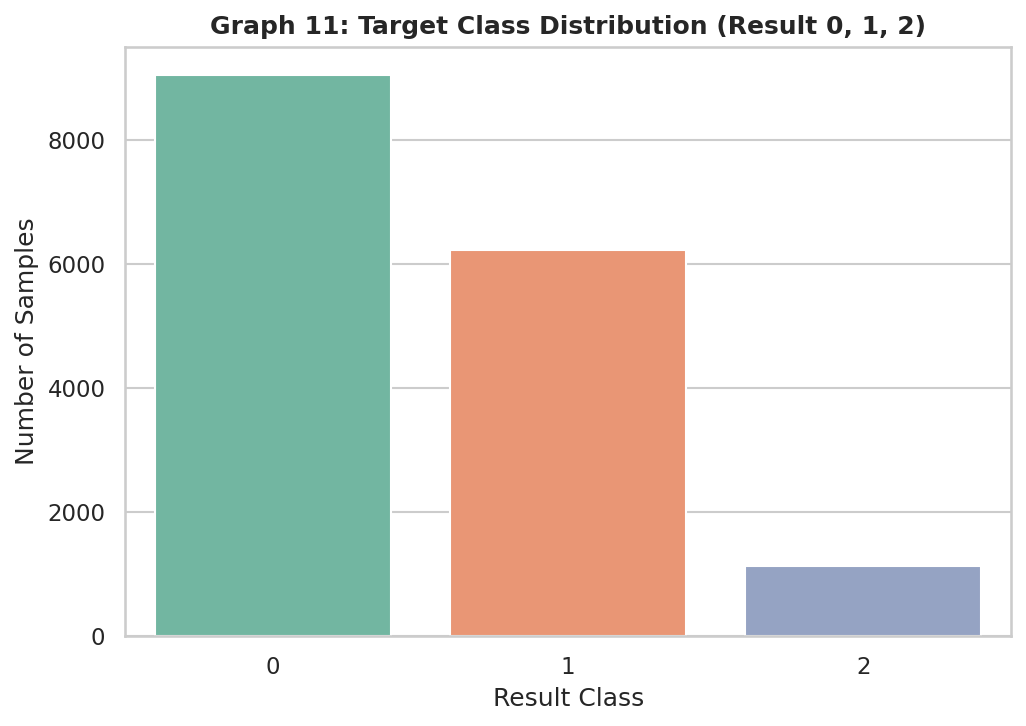

In [34]:
# Graph 11: Target Class Distribution

# Create classification target
y_clf = clf_df['result'].copy()

fig, ax = plt.subplots(figsize=(7, 5))

sns.countplot(
    x=y_clf,
    hue=y_clf,
    palette='Set2',
    legend=False,
    ax=ax
)

ax.set_title(
    'Graph 11: Target Class Distribution (Result 0, 1, 2)',
    fontsize=12,
    fontweight='bold'
)

ax.set_xlabel('Result Class')
ax.set_ylabel('Number of Samples')

plt.tight_layout()
plt.show()

### Interpretation

Class 0 represents approximately 55% of the dataset, Class 1 approximately 38%, and Class 2 approximately 7%. This shows that the dataset is imbalanced, with Class 2 having the fewest samples.

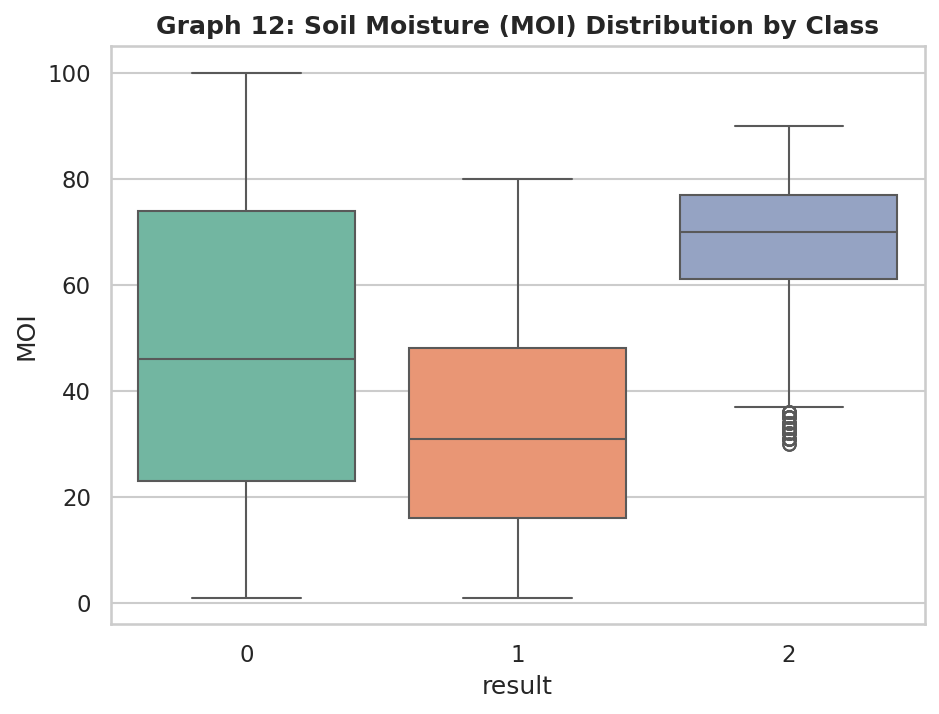

In [35]:
# Graph 12: Soil Moisture (MOI) Boxplot
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=clf_df, x='result', y='MOI', hue='result', ax=ax, palette='Set2', legend=False)
ax.set_title('Graph 12: Soil Moisture (MOI) Distribution by Class', fontsize=12, fontweight='bold')
plt.show()

### Interpretation

The boxplot shows the distribution of MOI values across Classes 0, 1, and 2. The distributions differ between the classes, indicating that MOI may help distinguish the classes.

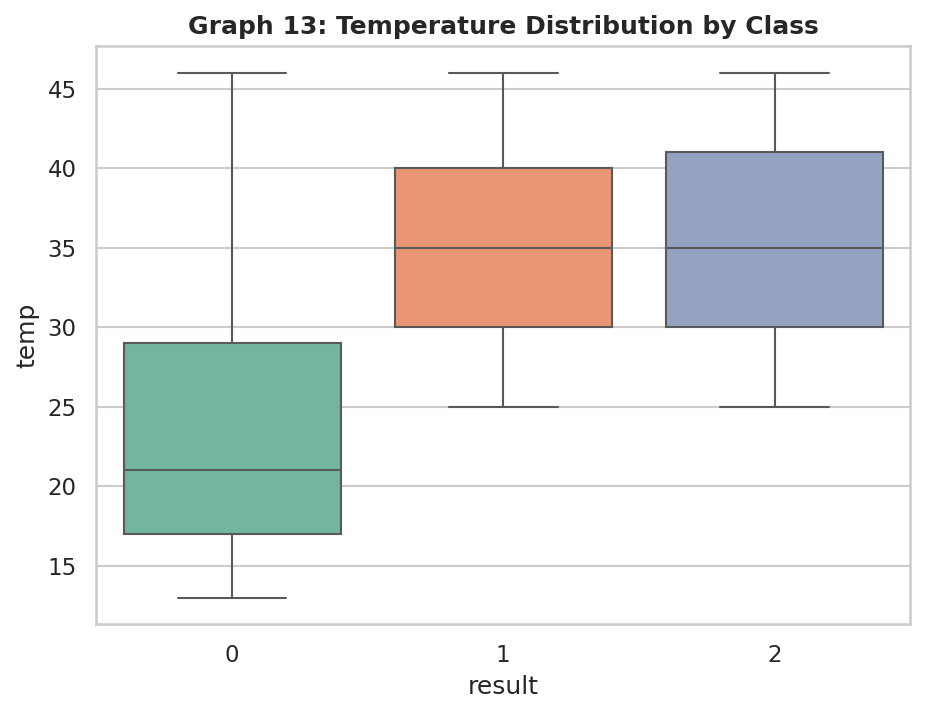

In [36]:
# Graph 13: Temperature Boxplot
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=clf_df, x='result', y='temp', hue='result', ax=ax, palette='Set2', legend=False)
ax.set_title('Graph 13: Temperature Distribution by Class', fontsize=12, fontweight='bold')
plt.show()

### Interpretation

The boxplot shows the distribution of temperature for Classes 0, 1, and 2. The temperature distributions differ across the three classes, indicating that temperature may help distinguish between the classes.

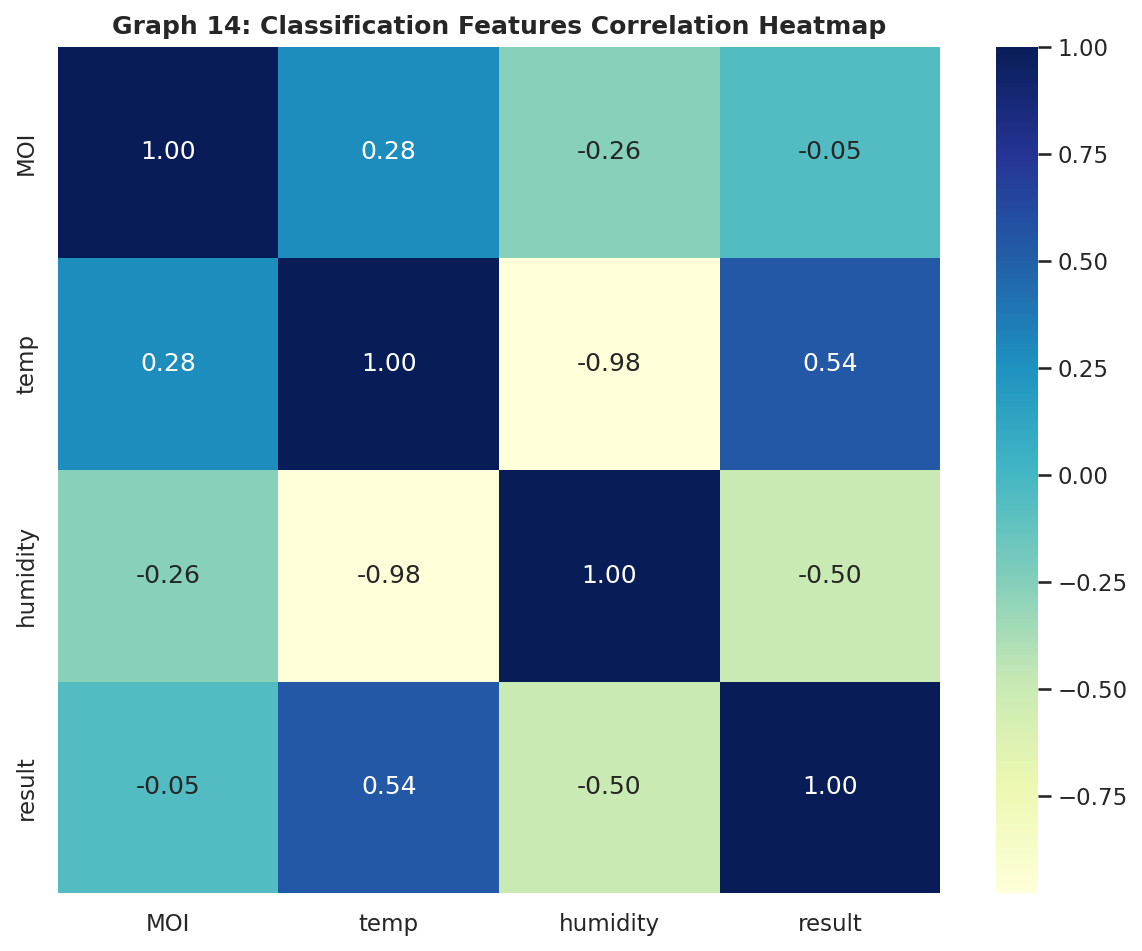

In [37]:
# Graph 14: Classification Features Correlation Heatmap

# Select numeric columns automatically
numeric_clf = clf_df.select_dtypes(include='number')

fig, ax = plt.subplots(figsize=(8, 6.5))

sns.heatmap(
    numeric_clf.corr(),
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    ax=ax,
    cbar=True
)

ax.set_title(
    'Graph 14: Classification Features Correlation Heatmap',
    fontsize=12,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

### Interpretation

The heatmap shows the correlation between the numerical features and the target variable. Temperature has a positive correlation with the result (0.54), while humidity has a negative correlation (-0.50). MOI has a weak correlation with the result (-0.05).

# Classification Preprocessing & Feature Engineering

This section prepares the classification dataset for machine learning.

The following steps are performed:

1. Check missing values and duplicates
2. Handle duplicate records
3. Check numerical features for outliers
4. Create the engineered feature `Temp_Humidity_Ratio`
5. Separate features and target
6. Perform a stratified 80:20 train-test split
7. Apply One-Hot Encoding to categorical features
8. Apply Standard Scaling to numerical features
9. Fit preprocessing only on the training data

In [38]:
# Missing Values and Duplicate Check

print("Missing Values:")
print(clf_df.isnull().sum())

print("\nNumber of Duplicate Rows:")
print(clf_df.duplicated().sum())

print("\nData Types:")
print(clf_df.dtypes)

Missing Values:
crop ID           0
soil_type         0
Seedling Stage    0
MOI               0
temp              0
humidity          0
result            0
dtype: int64

Number of Duplicate Rows:
128

Data Types:
crop ID               str
soil_type             str
Seedling Stage        str
MOI                 int64
temp                int64
humidity          float64
result              int64
dtype: object


### Duplicate Handling

The dataset contains duplicate records. Duplicate rows are removed so that repeated observations do not give additional weight to particular samples during model training.

In [39]:
# Remove Duplicate Rows

before_duplicates = len(clf_df)

clf_df = clf_df.drop_duplicates().reset_index(drop=True)

after_duplicates = len(clf_df)

print("Rows before removing duplicates:", before_duplicates)
print("Rows after removing duplicates:", after_duplicates)
print("Duplicates removed:", before_duplicates - after_duplicates)

Rows before removing duplicates: 16411
Rows after removing duplicates: 16283
Duplicates removed: 128


### Outlier Checking

Outliers are checked in the numerical variables using the IQR method. Since the numerical variables have bounded and realistic ranges in this dataset, observations outside the IQR limits are identified before model training.

In [40]:
# Outlier Check using IQR

numeric_cols_clf = ['MOI', 'temp', 'humidity']

for col in numeric_cols_clf:
    Q1 = clf_df[col].quantile(0.25)
    Q3 = clf_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = clf_df[
        (clf_df[col] < lower_bound) |
        (clf_df[col] > upper_bound)
    ]

    print(f"{col}:")
    print(f"  Lower Bound = {lower_bound:.2f}")
    print(f"  Upper Bound = {upper_bound:.2f}")
    print(f"  Outliers = {len(outliers)}")

MOI:
  Lower Bound = -43.50
  Upper Bound = 128.50
  Outliers = 0
temp:
  Lower Bound = -3.00
  Upper Bound = 61.00
  Outliers = 0
humidity:
  Lower Bound = -14.50
  Upper Bound = 141.50
  Outliers = 0


### Outlier Treatment

The IQR analysis did not identify outliers in MOI, temperature, or humidity. Therefore, no observations were removed or modified on the basis of outlier detection.

### Feature Engineering

A new feature, `Temp_Humidity_Ratio`, is created by dividing temperature by humidity.

This feature represents the relative temperature level with respect to atmospheric humidity and may provide additional information to the classification models beyond the individual variables.

In [41]:
# Feature Engineering

clf_df['Temp_Humidity_Ratio'] = (
    clf_df['temp'] / (clf_df['humidity'] + 1e-5)
)

print("Engineered feature created: Temp_Humidity_Ratio")

print(
    clf_df[
        ['temp', 'humidity', 'Temp_Humidity_Ratio']
    ].head()
)

Engineered feature created: Temp_Humidity_Ratio
   temp  humidity  Temp_Humidity_Ratio
0    25      80.0             0.312500
1    26      77.0             0.337662
2    27      74.0             0.364865
3    28      71.0             0.394366
4    29      68.0             0.426471


In [42]:
# Final Dataset Check After Cleaning and Feature Engineering

print("Final Shape:", clf_df.shape)

print("\nColumns:")
print(clf_df.columns.tolist())

print("\nMissing Values:")
print(clf_df.isnull().sum())

Final Shape: (16283, 8)

Columns:
['crop ID', 'soil_type', 'Seedling Stage', 'MOI', 'temp', 'humidity', 'result', 'Temp_Humidity_Ratio']

Missing Values:
crop ID                0
soil_type              0
Seedling Stage         0
MOI                    0
temp                   0
humidity               0
result                 0
Temp_Humidity_Ratio    0
dtype: int64


### Feature and Target Separation

The target variable is `result`. All remaining columns are used as input features.

In [43]:
# Separate Features and Target

X_clf = clf_df.drop(columns=['result'])
y_clf = clf_df['result']

print("Feature Shape:", X_clf.shape)
print("Target Shape:", y_clf.shape)

print("\nTarget Distribution:")
print(y_clf.value_counts().sort_index())

Feature Shape: (16283, 7)
Target Shape: (16283,)

Target Distribution:
result
0    8934
1    6227
2    1122
Name: count, dtype: int64


### Stratified Train-Test Split

The dataset is divided into 80% training data and 20% testing data.

Stratification is used so that the proportion of classes 0, 1, and 2 remains approximately the same in both datasets.

In [44]:
# Stratified 80:20 Train-Test Split

from sklearn.model_selection import train_test_split

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf,
    y_clf,
    test_size=0.20,
    random_state=42,
    stratify=y_clf
)

print("Training samples:", X_train_clf.shape[0])
print("Testing samples:", X_test_clf.shape[0])

print("\nTraining Class Distribution:")
print(y_train_clf.value_counts(normalize=True).sort_index())

print("\nTesting Class Distribution:")
print(y_test_clf.value_counts(normalize=True).sort_index())

Training samples: 13026
Testing samples: 3257

Training Class Distribution:
result
0    0.548672
1    0.382389
2    0.068939
Name: proportion, dtype: float64

Testing Class Distribution:
result
0    0.548664
1    0.382561
2    0.068775
Name: proportion, dtype: float64


### One-Hot Encoding and Standard Scaling

Categorical variables are converted into numerical form using One-Hot Encoding.

Numerical variables are standardized using StandardScaler.

The encoder and scaler are fitted only on the training data and then applied to the test data to prevent data leakage.

In [45]:
# Define Categorical and Numerical Features

categorical_cols_clf = [
    'crop ID',
    'soil_type',
    'Seedling Stage'
]

numerical_cols_clf = [
    'MOI',
    'temp',
    'humidity',
    'Temp_Humidity_Ratio'
]

print("Categorical Features:")
print(categorical_cols_clf)

print("\nNumerical Features:")
print(numerical_cols_clf)

Categorical Features:
['crop ID', 'soil_type', 'Seedling Stage']

Numerical Features:
['MOI', 'temp', 'humidity', 'Temp_Humidity_Ratio']


In [46]:
# One-Hot Encoding + Standard Scaling

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor_clf = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_cols_clf
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_cols_clf
        )
    ]
)

In [47]:
# Fit Preprocessor on Training Data Only

X_train_clf_prep = preprocessor_clf.fit_transform(X_train_clf)

X_test_clf_prep = preprocessor_clf.transform(X_test_clf)

print("Preprocessing completed successfully.")
print("Training matrix shape:", X_train_clf_prep.shape)
print("Testing matrix shape:", X_test_clf_prep.shape)

Preprocessing completed successfully.
Training matrix shape: (13026, 24)
Testing matrix shape: (3257, 24)


In [48]:
# Final Preprocessing Verification

print("X_train_clf shape:", X_train_clf.shape)
print("X_test_clf shape:", X_test_clf.shape)

print("X_train_clf_prep shape:", X_train_clf_prep.shape)
print("X_test_clf_prep shape:", X_test_clf_prep.shape)

print("\nTraining target distribution:")
print(y_train_clf.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test_clf.value_counts().sort_index())

X_train_clf shape: (13026, 7)
X_test_clf shape: (3257, 7)
X_train_clf_prep shape: (13026, 24)
X_test_clf_prep shape: (3257, 24)

Training target distribution:
result
0    7147
1    4981
2     898
Name: count, dtype: int64

Testing target distribution:
result
0    1787
1    1246
2     224
Name: count, dtype: int64


### Algorithm 1: Logistic Regression (Baseline Classifier)
- **Concept**: Multi-class logistic baseline utilizing Softmax/OvR probability modeling.

In [73]:

# ============================================================
# Algorithm 1: Logistic Regression
# Training & Evaluation
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Prepare Classification Data
# ------------------------------------------------------------

clf_model_df = clf_df.drop_duplicates().copy()

y_clf = clf_model_df['result']
X_clf = clf_model_df.drop(columns=['result'])

cat_cols_clf = [
    'crop ID',
    'soil_type',
    'Seedling Stage'
]

num_cols_clf = [
    'MOI',
    'temp',
    'humidity',
    'Temp_Humidity_Ratio'
]

# ------------------------------------------------------------
# Stratified 80:20 Train-Test Split
# ------------------------------------------------------------

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf,
    y_clf,
    test_size=0.20,
    random_state=42,
    stratify=y_clf
)

print("Training data shape:", X_train_clf.shape)
print("Testing data shape :", X_test_clf.shape)

# ------------------------------------------------------------
# Preprocessing
# ------------------------------------------------------------

preprocessor_clf = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            cat_cols_clf
        ),
        (
            'numerical',
            StandardScaler(),
            num_cols_clf
        )
    ]
)

X_train_clf_prep = preprocessor_clf.fit_transform(
    X_train_clf
)

X_test_clf_prep = preprocessor_clf.transform(
    X_test_clf
)

print("\nPreprocessing completed successfully.")
print("Processed training shape:", X_train_clf_prep.shape)
print("Processed testing shape :", X_test_clf_prep.shape)

# ------------------------------------------------------------
# Train Logistic Regression
# ------------------------------------------------------------

lr_clf = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_lr_clf = lr_clf.predict(
    X_test_clf_prep
)

probs_lr_clf = lr_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_lr = accuracy_score(
    y_test_clf,
    preds_lr_clf
)

precision_lr = precision_score(
    y_test_clf,
    preds_lr_clf,
    average='weighted',
    zero_division=0
)

recall_lr = recall_score(
    y_test_clf,
    preds_lr_clf,
    average='weighted',
    zero_division=0
)

f1_lr = f1_score(
    y_test_clf,
    preds_lr_clf,
    average='weighted',
    zero_division=0
)

roc_lr = roc_auc_score(
    y_test_clf,
    probs_lr_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("\n=== Algorithm 1: Logistic Regression ===")
print(f"Accuracy          : {acc_lr:.4f} ({acc_lr * 100:.2f}%)")
print(f"Weighted Precision: {precision_lr:.4f}")
print(f"Weighted Recall   : {recall_lr:.4f}")
print(f"Weighted F1-score : {f1_lr:.4f}")
print(f"ROC-AUC (OvR)     : {roc_lr:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_lr_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_lr_clf,
    zero_division=0
))


Training data shape: (13026, 7)
Testing data shape : (3257, 7)

Preprocessing completed successfully.
Processed training shape: (13026, 24)
Processed testing shape : (3257, 24)

=== Algorithm 1: Logistic Regression ===
Accuracy          : 0.8290 (82.90%)
Weighted Precision: 0.7797
Weighted Recall   : 0.8290
Weighted F1-score : 0.8020
ROC-AUC (OvR)     : 0.9438

Confusion Matrix:
[[1618  152   17]
 [ 165 1081    0]
 [ 131   92    1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.91      0.87      1787
           1       0.82      0.87      0.84      1246
           2       0.06      0.00      0.01       224

    accuracy                           0.83      3257
   macro avg       0.57      0.59      0.57      3257
weighted avg       0.78      0.83      0.80      3257



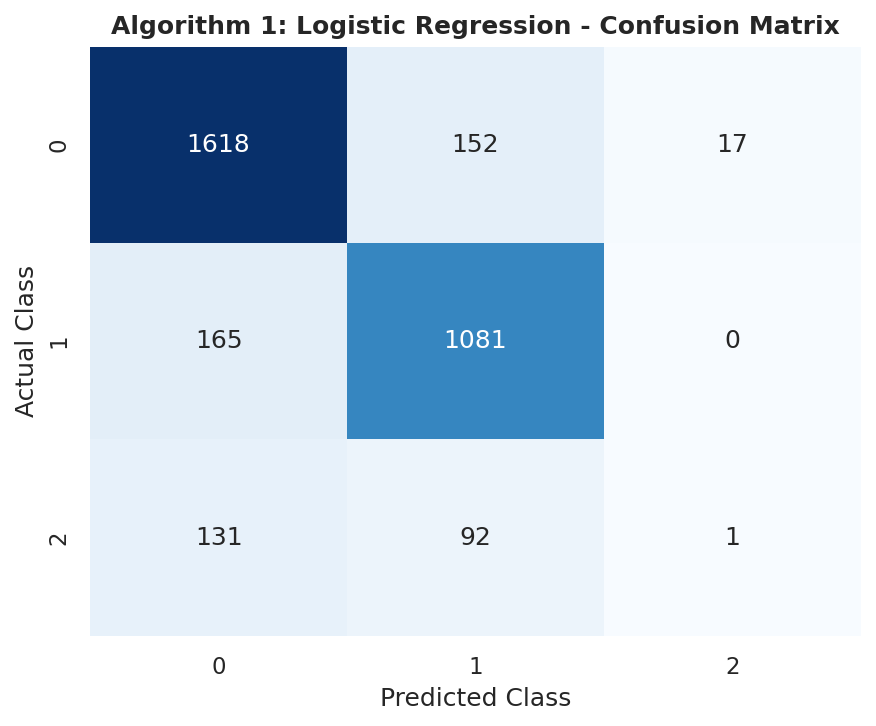

In [51]:
# ============================================================
# Algorithm 1 Visualization: Logistic Regression
# Confusion Matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate confusion matrix
cm_lr = confusion_matrix(
    y_test_clf,
    preds_lr_clf
)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 1: Logistic Regression - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


### Interpretation — Logistic Regression

- **Accuracy:** Evaluate the overall percentage of correct predictions.
- **Precision and Recall:** Examine the weighted precision and recall values.
- **Weighted F1-score:** Assess the balance between precision and recall.
- **ROC-AUC:** Evaluate class discrimination using the One-vs-Rest approach.
- **Confusion Matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Conclusion:** Compare Logistic Regression with the other classifiers using the actual evaluation results.


### Algorithm 2: K-Nearest Neighbors Classifier (Top Classifier)
- **Concept**: Instance-based voting using $k=5$ nearest neighbors weighted by inverse Euclidean distance.

In [69]:

# ============================================================
# Algorithm 2: K-Nearest Neighbors Classifier
# Training & Evaluation
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create KNN Model
# ------------------------------------------------------------

knn_clf = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance'
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

knn_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_knn_clf = knn_clf.predict(
    X_test_clf_prep
)

probs_knn_clf = knn_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_knn = accuracy_score(
    y_test_clf,
    preds_knn_clf
)

precision_knn = precision_score(
    y_test_clf,
    preds_knn_clf,
    average='weighted',
    zero_division=0
)

recall_knn = recall_score(
    y_test_clf,
    preds_knn_clf,
    average='weighted',
    zero_division=0
)

f1_knn = f1_score(
    y_test_clf,
    preds_knn_clf,
    average='weighted',
    zero_division=0
)

roc_knn = roc_auc_score(
    y_test_clf,
    probs_knn_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 2: K-Nearest Neighbors ===")
print(f"Accuracy          : {acc_knn:.4f} ({acc_knn * 100:.2f}%)")
print(f"Weighted Precision: {precision_knn:.4f}")
print(f"Weighted Recall   : {recall_knn:.4f}")
print(f"Weighted F1-score : {f1_knn:.4f}")
print(f"ROC-AUC (OvR)     : {roc_knn:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_knn_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_knn_clf,
    zero_division=0
))


=== Algorithm 2: K-Nearest Neighbors ===
Accuracy          : 0.9527 (95.27%)
Weighted Precision: 0.9528
Weighted Recall   : 0.9527
Weighted F1-score : 0.9523
ROC-AUC (OvR)     : 0.9942

Confusion Matrix:
[[1758   15   14]
 [  74 1161   11]
 [  22   18  184]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      1787
           1       0.97      0.93      0.95      1246
           2       0.88      0.82      0.85       224

    accuracy                           0.95      3257
   macro avg       0.93      0.91      0.92      3257
weighted avg       0.95      0.95      0.95      3257



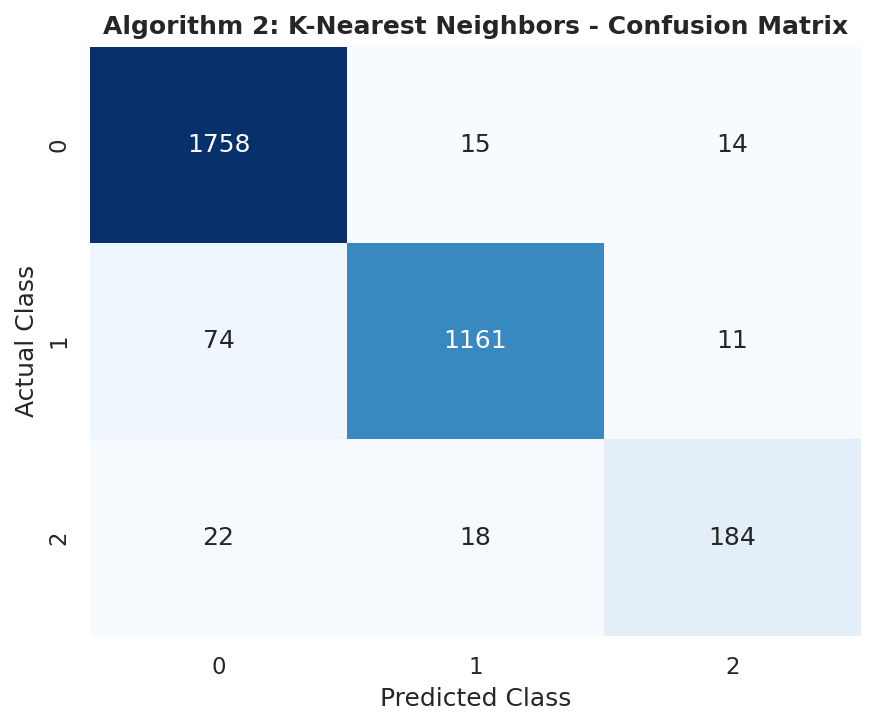

In [75]:
# ============================================================
# Algorithm 2 Visualization: KNN Confusion Matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_knn = confusion_matrix(
    y_test_clf,
    preds_knn_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 2: K-Nearest Neighbors - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


### Interpretation — K-Nearest Neighbors

- **Accuracy:** Evaluate the overall percentage of correct predictions.
- **Precision and Recall:** Examine the weighted precision and recall values.
- **Weighted F1-score:** Assess the balance between precision and recall.
- **ROC-AUC:** Evaluate class discrimination using the One-vs-Rest approach.
- **Confusion Matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Conclusion:** Compare KNN with the other classifiers using the actual evaluation results.


### Algorithm 3: Naive Bayes (GaussianNB)
- **Concept**: Probabilistic classifier assuming conditional feature independence given class label.

In [70]:

# ============================================================
# Algorithm 3: Gaussian Naive Bayes
# Training & Evaluation
# ============================================================

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create Gaussian Naive Bayes Model
# ------------------------------------------------------------

nb_clf = GaussianNB()

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

nb_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_nb_clf = nb_clf.predict(
    X_test_clf_prep
)

probs_nb_clf = nb_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_nb = accuracy_score(
    y_test_clf,
    preds_nb_clf
)

precision_nb = precision_score(
    y_test_clf,
    preds_nb_clf,
    average='weighted',
    zero_division=0
)

recall_nb = recall_score(
    y_test_clf,
    preds_nb_clf,
    average='weighted',
    zero_division=0
)

f1_nb = f1_score(
    y_test_clf,
    preds_nb_clf,
    average='weighted',
    zero_division=0
)

roc_nb = roc_auc_score(
    y_test_clf,
    probs_nb_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 3: Gaussian Naive Bayes ===")
print(f"Accuracy          : {acc_nb:.4f} ({acc_nb * 100:.2f}%)")
print(f"Weighted Precision: {precision_nb:.4f}")
print(f"Weighted Recall   : {recall_nb:.4f}")
print(f"Weighted F1-score : {f1_nb:.4f}")
print(f"ROC-AUC (OvR)     : {roc_nb:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_nb_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_nb_clf,
    zero_division=0
))


=== Algorithm 3: Gaussian Naive Bayes ===
Accuracy          : 0.7347 (73.47%)
Weighted Precision: 0.7785
Weighted Recall   : 0.7347
Weighted F1-score : 0.7471
ROC-AUC (OvR)     : 0.8973

Confusion Matrix:
[[1483   41  263]
 [ 372  822   52]
 [  85   51   88]]

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.83      0.80      1787
           1       0.90      0.66      0.76      1246
           2       0.22      0.39      0.28       224

    accuracy                           0.73      3257
   macro avg       0.63      0.63      0.61      3257
weighted avg       0.78      0.73      0.75      3257



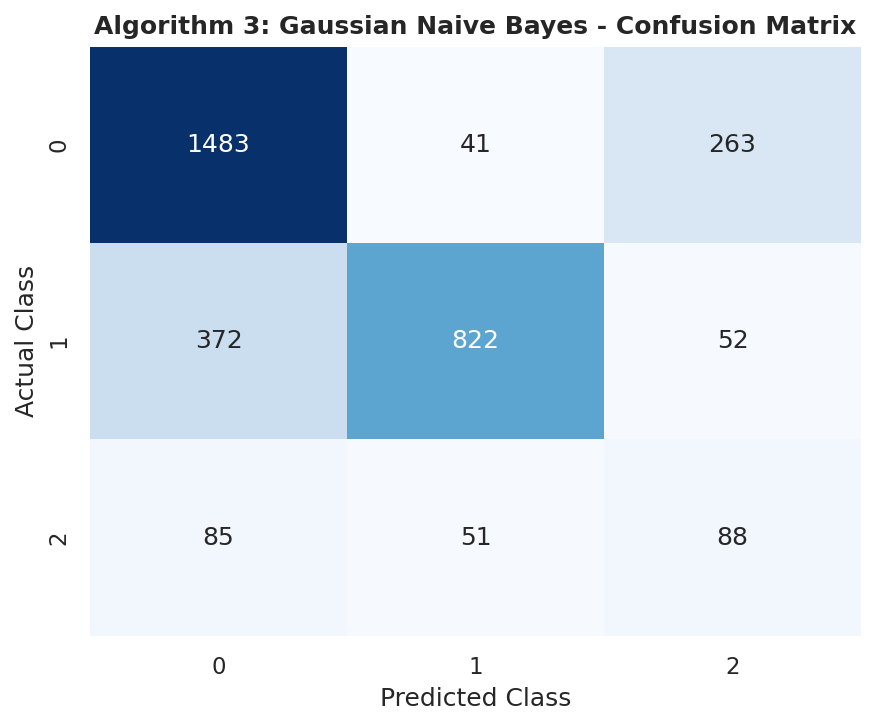

In [54]:
# ============================================================
# Algorithm 3 Visualization: Gaussian Naive Bayes
# Confusion Matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_nb = confusion_matrix(
    y_test_clf,
    preds_nb_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 3: Gaussian Naive Bayes - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


### Interpretation — Gaussian Naive Bayes

- **Accuracy:** Evaluate the overall percentage of correct predictions.
- **Precision and Recall:** Examine the weighted precision and recall values.
- **Weighted F1-score:** Assess the balance between precision and recall.
- **ROC-AUC:** Evaluate class discrimination using the One-vs-Rest approach.
- **Confusion Matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Conclusion:** Compare Gaussian Naive Bayes with the other classifiers using the actual evaluation results.


### Algorithm 4: Decision Tree Classifier
- **Concept**: Rule-based decision splits (`max_depth=5`) optimizing Gini impurity.

In [71]:

# ============================================================
# Algorithm 4: Decision Tree Classifier
# Training & Evaluation
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create Decision Tree Model
# ------------------------------------------------------------

dt_clf = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

dt_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_dt_clf = dt_clf.predict(
    X_test_clf_prep
)

probs_dt_clf = dt_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_dt_c = accuracy_score(
    y_test_clf,
    preds_dt_clf
)

precision_dt_c = precision_score(
    y_test_clf,
    preds_dt_clf,
    average='weighted',
    zero_division=0
)

recall_dt_c = recall_score(
    y_test_clf,
    preds_dt_clf,
    average='weighted',
    zero_division=0
)

f1_dt_c = f1_score(
    y_test_clf,
    preds_dt_clf,
    average='weighted',
    zero_division=0
)

roc_dt_c = roc_auc_score(
    y_test_clf,
    probs_dt_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 4: Decision Tree Classifier ===")
print(f"Accuracy          : {acc_dt_c:.4f} ({acc_dt_c * 100:.2f}%)")
print(f"Weighted Precision: {precision_dt_c:.4f}")
print(f"Weighted Recall   : {recall_dt_c:.4f}")
print(f"Weighted F1-score : {f1_dt_c:.4f}")
print(f"ROC-AUC (OvR)     : {roc_dt_c:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_dt_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_dt_clf,
    zero_division=0
))


=== Algorithm 4: Decision Tree Classifier ===
Accuracy          : 0.9113 (91.13%)
Weighted Precision: 0.9179
Weighted Recall   : 0.9113
Weighted F1-score : 0.8885
ROC-AUC (OvR)     : 0.9865

Confusion Matrix:
[[1714   73    0]
 [  16 1230    0]
 [ 104   96   24]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      1787
           1       0.88      0.99      0.93      1246
           2       1.00      0.11      0.19       224

    accuracy                           0.91      3257
   macro avg       0.94      0.68      0.69      3257
weighted avg       0.92      0.91      0.89      3257



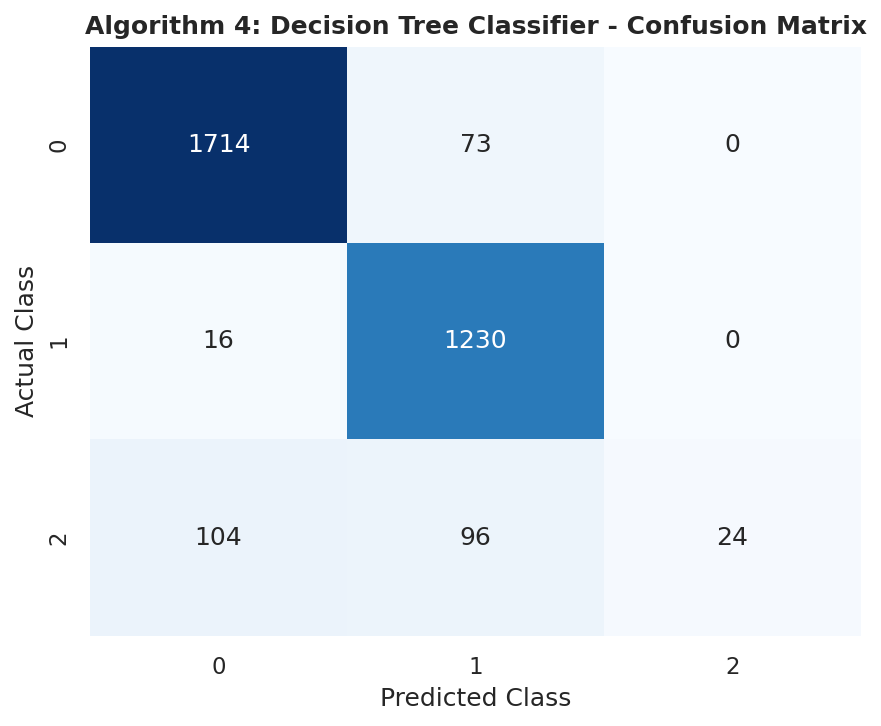

In [56]:
# ============================================================
# Algorithm 4 Visualization: Confusion Matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_dt = confusion_matrix(
    y_test_clf,
    preds_dt_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 4: Decision Tree Classifier - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


### Interpretation — Decision Tree Classifier

- **Accuracy:** Evaluate the overall percentage of correct predictions.
- **Precision and Recall:** Examine the weighted precision and recall values.
- **Weighted F1-score:** Assess the balance between precision and recall.
- **ROC-AUC:** Evaluate class discrimination using the One-vs-Rest approach.
- **Confusion Matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Model Complexity:** The tree uses a maximum depth of 5; evaluate its performance without assuming that a deeper tree would necessarily be better.
- **Conclusion:** Compare the Decision Tree with the other classifiers using the actual evaluation results.


### Algorithm 5: Support Vector Machine (SVC)
- **Concept**: Fits maximum margin hyperplanes in kernelized space with standardized inputs.

In [72]:

# ============================================================
# Algorithm 5: Support Vector Machine (SVC)
# Training & Evaluation
# ============================================================

import warnings
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Hide FutureWarning related to SVC
warnings.filterwarnings(
    "ignore",
    category=FutureWarning,
    module="sklearn.svm"
)

# ------------------------------------------------------------
# Create SVC Model
# ------------------------------------------------------------

svc_clf = SVC(
    kernel='rbf',
    C=1.0,
    probability=True,
    random_state=42
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

svc_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_svc_clf = svc_clf.predict(
    X_test_clf_prep
)

probs_svc_clf = svc_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_svc = accuracy_score(
    y_test_clf,
    preds_svc_clf
)

precision_svc = precision_score(
    y_test_clf,
    preds_svc_clf,
    average='weighted',
    zero_division=0
)

recall_svc = recall_score(
    y_test_clf,
    preds_svc_clf,
    average='weighted',
    zero_division=0
)

f1_svc = f1_score(
    y_test_clf,
    preds_svc_clf,
    average='weighted',
    zero_division=0
)

roc_svc = roc_auc_score(
    y_test_clf,
    probs_svc_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 5: Support Vector Machine (SVC) ===")
print(f"Accuracy          : {acc_svc:.4f} ({acc_svc * 100:.2f}%)")
print(f"Weighted Precision: {precision_svc:.4f}")
print(f"Weighted Recall   : {recall_svc:.4f}")
print(f"Weighted F1-score : {f1_svc:.4f}")
print(f"ROC-AUC (OvR)     : {roc_svc:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_svc_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_svc_clf,
    zero_division=0
))


=== Algorithm 5: Support Vector Machine (SVC) ===
Accuracy          : 0.9506 (95.06%)
Weighted Precision: 0.9486
Weighted Recall   : 0.9506
Weighted F1-score : 0.9484
ROC-AUC (OvR)     : 0.9956

Confusion Matrix:
[[1764    5   18]
 [  41 1193   12]
 [  57   28  139]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97      1787
           1       0.97      0.96      0.97      1246
           2       0.82      0.62      0.71       224

    accuracy                           0.95      3257
   macro avg       0.91      0.86      0.88      3257
weighted avg       0.95      0.95      0.95      3257



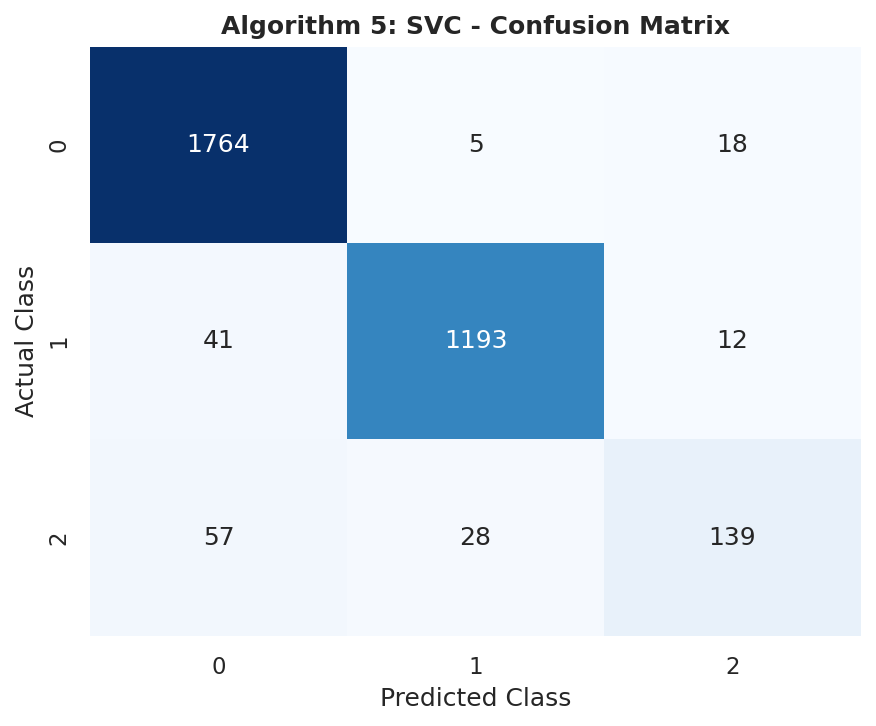

In [58]:
# ============================================================
# Algorithm 5: Confusion Matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_svc = confusion_matrix(
    y_test_clf,
    preds_svc_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_svc,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 5: SVC - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


### Interpretation — Support Vector Machine (SVC)

- **Accuracy:** Evaluate the overall percentage of correct predictions.
- **Precision and Recall:** Examine the weighted precision and recall values.
- **Weighted F1-score:** Assess the balance between precision and recall.
- **ROC-AUC:** Evaluate class discrimination using the One-vs-Rest approach.
- **Confusion Matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Kernel:** The RBF kernel allows the classifier to model nonlinear decision boundaries.
- **Conclusion:** Compare SVC with the other classifiers using the actual evaluation results.


## Classification Part B — Classification Algorithms

In this section, five additional classification algorithms are implemented and evaluated using the same classification dataset and train-test split as Part A. Their performance will be compared with the five existing models using accuracy, precision, recall, weighted F1-score, and ROC-AUC.

### Algorithm 6: Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees. It can capture nonlinear relationships and is less dependent on a single decision tree. The model will be evaluated using the same test data as the Part A classifiers.

In [59]:

# ============================================================
# Algorithm 6: Random Forest Classifier
# Training & Evaluation
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create Random Forest Model
# ------------------------------------------------------------

rf_clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

rf_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_rf_clf = rf_clf.predict(
    X_test_clf_prep
)

probs_rf_clf = rf_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_rf = accuracy_score(
    y_test_clf,
    preds_rf_clf
)

precision_rf = precision_score(
    y_test_clf,
    preds_rf_clf,
    average='weighted',
    zero_division=0
)

recall_rf = recall_score(
    y_test_clf,
    preds_rf_clf,
    average='weighted',
    zero_division=0
)

f1_rf = f1_score(
    y_test_clf,
    preds_rf_clf,
    average='weighted',
    zero_division=0
)

roc_rf = roc_auc_score(
    y_test_clf,
    probs_rf_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 6: Random Forest Classifier ===")
print(f"Accuracy          : {acc_rf:.4f} ({acc_rf * 100:.2f}%)")
print(f"Weighted Precision: {precision_rf:.4f}")
print(f"Weighted Recall   : {recall_rf:.4f}")
print(f"Weighted F1-score : {f1_rf:.4f}")
print(f"ROC-AUC (OvR)     : {roc_rf:.4f}")

# ------------------------------------------------------------
# Confusion Matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_rf_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_rf_clf,
    zero_division=0
))


=== Algorithm 6: Random Forest Classifier ===
Accuracy          : 0.9917 (99.17%)
Weighted Precision: 0.9916
Weighted Recall   : 0.9917
Weighted F1-score : 0.9917
ROC-AUC (OvR)     : 0.9999

Confusion Matrix:
[[1778    0    9]
 [   0 1244    2]
 [   8    8  208]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      1787
           1       0.99      1.00      1.00      1246
           2       0.95      0.93      0.94       224

    accuracy                           0.99      3257
   macro avg       0.98      0.97      0.98      3257
weighted avg       0.99      0.99      0.99      3257



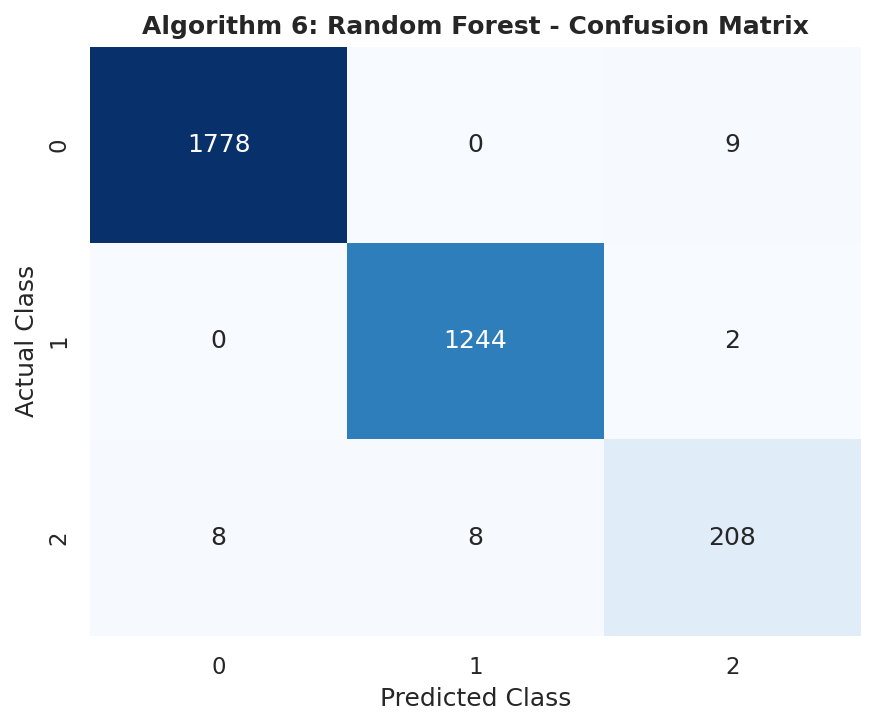

In [60]:

# ============================================================
# Algorithm 6: Confusion Matrix - Random Forest
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_rf = confusion_matrix(
    y_test_clf,
    preds_rf_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 6: Random Forest - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


### Interpretation — Random Forest Classifier

- **Overall performance:** Evaluate the model using its test accuracy and weighted F1-score.
- **Precision and recall:** Examine how well the model predicts each class and identifies actual instances.
- **ROC-AUC:** Assess how well the model distinguishes the three classes using the One-vs-Rest approach.
- **Confusion matrix:** Identify which classes are predicted correctly and which are confused.
- **Conclusion:** Decide whether the model performs well based on the actual results and compare it with the other classifiers.

### Algorithm 7: AdaBoost Classifier

AdaBoost is an ensemble learning algorithm that combines multiple weak learners into a stronger classifier. It gives more attention to observations that earlier learners classified incorrectly.

In [61]:

# ============================================================
# Algorithm 7: AdaBoost Classifier
# Training & Evaluation
# ============================================================

from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create AdaBoost Model
# ------------------------------------------------------------

ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

ada_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_ada_clf = ada_clf.predict(
    X_test_clf_prep
)

probs_ada_clf = ada_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_ada = accuracy_score(
    y_test_clf,
    preds_ada_clf
)

precision_ada = precision_score(
    y_test_clf,
    preds_ada_clf,
    average='weighted',
    zero_division=0
)

recall_ada = recall_score(
    y_test_clf,
    preds_ada_clf,
    average='weighted',
    zero_division=0
)

f1_ada = f1_score(
    y_test_clf,
    preds_ada_clf,
    average='weighted',
    zero_division=0
)

roc_ada = roc_auc_score(
    y_test_clf,
    probs_ada_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 7: AdaBoost Classifier ===")
print(f"Accuracy          : {acc_ada:.4f} ({acc_ada * 100:.2f}%)")
print(f"Weighted Precision: {precision_ada:.4f}")
print(f"Weighted Recall   : {recall_ada:.4f}")
print(f"Weighted F1-score : {f1_ada:.4f}")
print(f"ROC-AUC (OvR)     : {roc_ada:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_ada_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_ada_clf,
    zero_division=0
))


=== Algorithm 7: AdaBoost Classifier ===
Accuracy          : 0.9085 (90.85%)
Weighted Precision: 0.9002
Weighted Recall   : 0.9085
Weighted F1-score : 0.9035
ROC-AUC (OvR)     : 0.9602

Confusion Matrix:
[[1690   39   58]
 [  15 1196   35]
 [  74   77   73]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      1787
           1       0.91      0.96      0.94      1246
           2       0.44      0.33      0.37       224

    accuracy                           0.91      3257
   macro avg       0.77      0.74      0.75      3257
weighted avg       0.90      0.91      0.90      3257



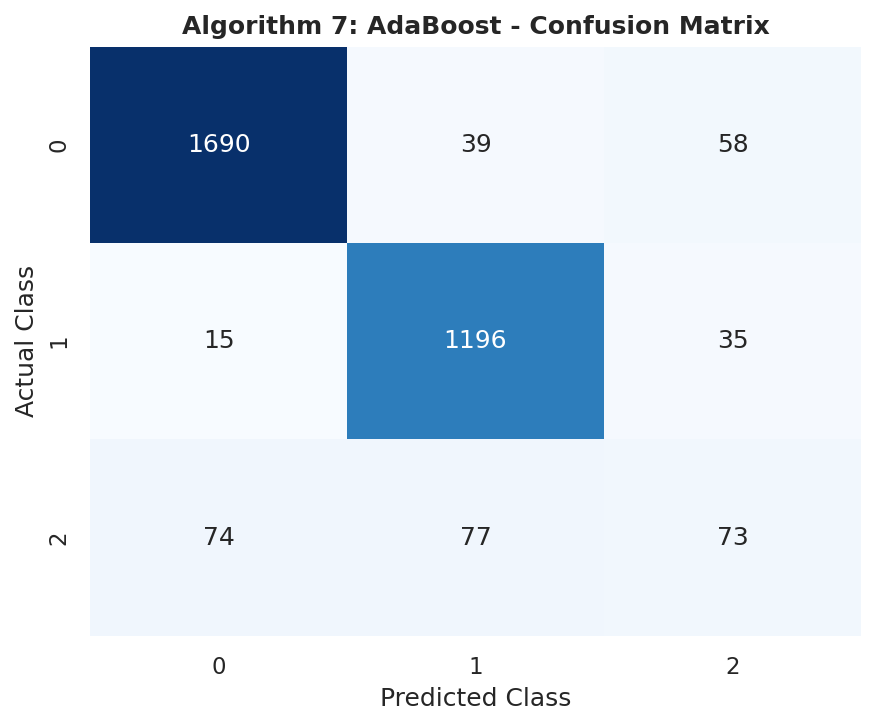

In [62]:

# ============================================================
# Algorithm 7: Confusion Matrix - AdaBoost
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_ada = confusion_matrix(
    y_test_clf,
    preds_ada_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_ada,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 7: AdaBoost - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


### Interpretation — AdaBoost Classifier

- **Overall performance:** Evaluate the test accuracy and weighted F1-score.
- **Precision and recall:** Check how effectively the model predicts each class.
- **ROC-AUC:** Assess its ability to distinguish the three classes using One-vs-Rest.
- **Confusion matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Conclusion:** Judge the model's performance using the actual results and compare it with the other classifiers.


### Algorithm 8: Gradient Boosting Classifier

Gradient Boosting builds an ensemble of decision trees sequentially. Each new tree attempts to improve the predictions made by the existing ensemble.


In [63]:

# ============================================================
# Algorithm 8: Gradient Boosting Classifier
# Training & Evaluation
# ============================================================

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create Gradient Boosting Model
# ------------------------------------------------------------

gb_clf = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

gb_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_gb_clf = gb_clf.predict(
    X_test_clf_prep
)

probs_gb_clf = gb_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_gb = accuracy_score(
    y_test_clf,
    preds_gb_clf
)

precision_gb = precision_score(
    y_test_clf,
    preds_gb_clf,
    average='weighted',
    zero_division=0
)

recall_gb = recall_score(
    y_test_clf,
    preds_gb_clf,
    average='weighted',
    zero_division=0
)

f1_gb = f1_score(
    y_test_clf,
    preds_gb_clf,
    average='weighted',
    zero_division=0
)

roc_gb = roc_auc_score(
    y_test_clf,
    probs_gb_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 8: Gradient Boosting Classifier ===")
print(f"Accuracy          : {acc_gb:.4f} ({acc_gb * 100:.2f}%)")
print(f"Weighted Precision: {precision_gb:.4f}")
print(f"Weighted Recall   : {recall_gb:.4f}")
print(f"Weighted F1-score : {f1_gb:.4f}")
print(f"ROC-AUC (OvR)     : {roc_gb:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_gb_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_gb_clf,
    zero_division=0
))


=== Algorithm 8: Gradient Boosting Classifier ===
Accuracy          : 0.9675 (96.75%)
Weighted Precision: 0.9661
Weighted Recall   : 0.9675
Weighted F1-score : 0.9649
ROC-AUC (OvR)     : 0.9983

Confusion Matrix:
[[1773    5    9]
 [   0 1239    7]
 [  29   56  139]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1787
           1       0.95      0.99      0.97      1246
           2       0.90      0.62      0.73       224

    accuracy                           0.97      3257
   macro avg       0.94      0.87      0.90      3257
weighted avg       0.97      0.97      0.96      3257



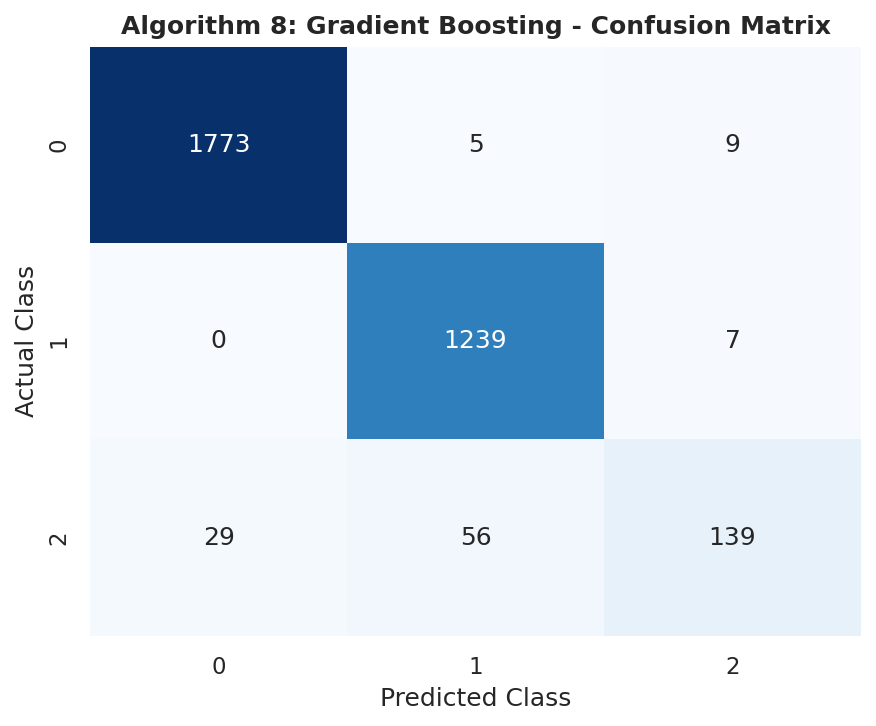

In [64]:

# ============================================================
# Algorithm 8: Confusion Matrix - Gradient Boosting
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_gb = confusion_matrix(
    y_test_clf,
    preds_gb_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 8: Gradient Boosting - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()



### Interpretation — Gradient Boosting Classifier

- **Overall performance:** Evaluate the test accuracy and weighted F1-score.
- **Precision and recall:** Examine how effectively the model predicts each class.
- **ROC-AUC:** Assess its ability to distinguish the three classes using One-vs-Rest.
- **Confusion matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Conclusion:** Judge the model using the actual results and compare it with the other classifiers.



### Algorithm 9: Bagging Classifier

Bagging (Bootstrap Aggregating) trains multiple models on different bootstrap samples of the training data and combines their predictions. We use Decision Trees as the base estimators, as required by the project rubric.


In [65]:

# ============================================================
# Algorithm 9: Bagging Classifier
# Training & Evaluation
# ============================================================

from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create Bagging Model
# Decision Tree is the base estimator
# ------------------------------------------------------------

bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    max_samples=1.0,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

bag_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_bag_clf = bag_clf.predict(
    X_test_clf_prep
)

probs_bag_clf = bag_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_bag = accuracy_score(
    y_test_clf,
    preds_bag_clf
)

precision_bag = precision_score(
    y_test_clf,
    preds_bag_clf,
    average='weighted',
    zero_division=0
)

recall_bag = recall_score(
    y_test_clf,
    preds_bag_clf,
    average='weighted',
    zero_division=0
)

f1_bag = f1_score(
    y_test_clf,
    preds_bag_clf,
    average='weighted',
    zero_division=0
)

roc_bag = roc_auc_score(
    y_test_clf,
    probs_bag_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 9: Bagging Classifier ===")
print(f"Accuracy          : {acc_bag:.4f} ({acc_bag * 100:.2f}%)")
print(f"Weighted Precision: {precision_bag:.4f}")
print(f"Weighted Recall   : {recall_bag:.4f}")
print(f"Weighted F1-score : {f1_bag:.4f}")
print(f"ROC-AUC (OvR)     : {roc_bag:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_bag_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_bag_clf,
    zero_division=0
))


=== Algorithm 9: Bagging Classifier ===
Accuracy          : 0.9975 (99.75%)
Weighted Precision: 0.9975
Weighted Recall   : 0.9975
Weighted F1-score : 0.9975
ROC-AUC (OvR)     : 0.9999

Confusion Matrix:
[[1786    0    1]
 [   0 1245    1]
 [   3    3  218]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1787
           1       1.00      1.00      1.00      1246
           2       0.99      0.97      0.98       224

    accuracy                           1.00      3257
   macro avg       1.00      0.99      0.99      3257
weighted avg       1.00      1.00      1.00      3257



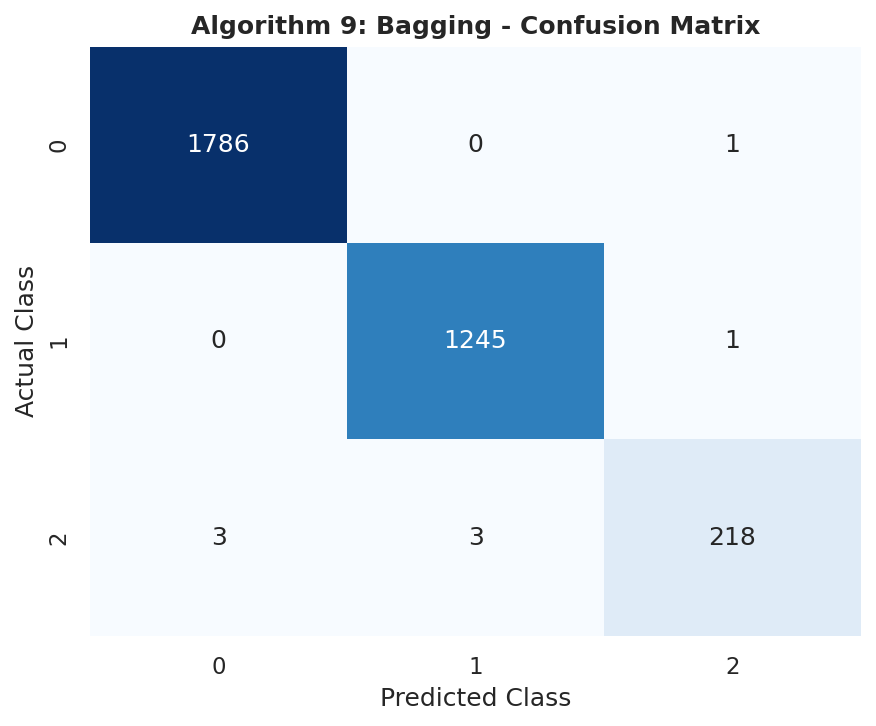

In [66]:

# ============================================================
# Algorithm 9: Confusion Matrix - Bagging
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_bag = confusion_matrix(
    y_test_clf,
    preds_bag_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_bag,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 9: Bagging - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()



### Interpretation — Bagging Classifier

- **Overall performance:** Evaluate the test accuracy and weighted F1-score.
- **Precision and recall:** Examine how effectively the model predicts each class.
- **ROC-AUC:** Assess its ability to distinguish the three classes using One-vs-Rest.
- **Confusion matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Conclusion:** Judge the model using the actual results and compare it with the other classifiers.



### Algorithm 10: MLP Classifier (Neural Network)

The Multi-Layer Perceptron (MLP) is a neural network that learns patterns through interconnected layers of neurons. It can model complex, nonlinear relationships in data.


In [67]:

# ============================================================
# Algorithm 10: MLP Classifier (Neural Network)
# Training & Evaluation
# ============================================================

from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# Create MLP Model
# ------------------------------------------------------------

mlp_clf = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    random_state=42
)

# ------------------------------------------------------------
# Train the Model
# ------------------------------------------------------------

mlp_clf.fit(
    X_train_clf_prep,
    y_train_clf
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

preds_mlp_clf = mlp_clf.predict(
    X_test_clf_prep
)

probs_mlp_clf = mlp_clf.predict_proba(
    X_test_clf_prep
)

# ------------------------------------------------------------
# Evaluation Metrics
# ------------------------------------------------------------

acc_mlp = accuracy_score(
    y_test_clf,
    preds_mlp_clf
)

precision_mlp = precision_score(
    y_test_clf,
    preds_mlp_clf,
    average='weighted',
    zero_division=0
)

recall_mlp = recall_score(
    y_test_clf,
    preds_mlp_clf,
    average='weighted',
    zero_division=0
)

f1_mlp = f1_score(
    y_test_clf,
    preds_mlp_clf,
    average='weighted',
    zero_division=0
)

roc_mlp = roc_auc_score(
    y_test_clf,
    probs_mlp_clf,
    multi_class='ovr',
    average='weighted'
)

# ------------------------------------------------------------
# Display Results
# ------------------------------------------------------------

print("=== Algorithm 10: MLP Classifier ===")
print(f"Accuracy          : {acc_mlp:.4f} ({acc_mlp * 100:.2f}%)")
print(f"Weighted Precision: {precision_mlp:.4f}")
print(f"Weighted Recall   : {recall_mlp:.4f}")
print(f"Weighted F1-score : {f1_mlp:.4f}")
print(f"ROC-AUC (OvR)     : {roc_mlp:.4f}")

# ------------------------------------------------------------
# Confusion Matrix Values
# ------------------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_clf,
    preds_mlp_clf
))

# ------------------------------------------------------------
# Classification Report
# ------------------------------------------------------------

print("\nClassification Report:")
print(classification_report(
    y_test_clf,
    preds_mlp_clf,
    zero_division=0
))


=== Algorithm 10: MLP Classifier ===
Accuracy          : 0.9880 (98.80%)
Weighted Precision: 0.9879
Weighted Recall   : 0.9880
Weighted F1-score : 0.9880
ROC-AUC (OvR)     : 0.9997

Confusion Matrix:
[[1780    0    7]
 [   0 1236   10]
 [  17    5  202]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1787
           1       1.00      0.99      0.99      1246
           2       0.92      0.90      0.91       224

    accuracy                           0.99      3257
   macro avg       0.97      0.96      0.97      3257
weighted avg       0.99      0.99      0.99      3257



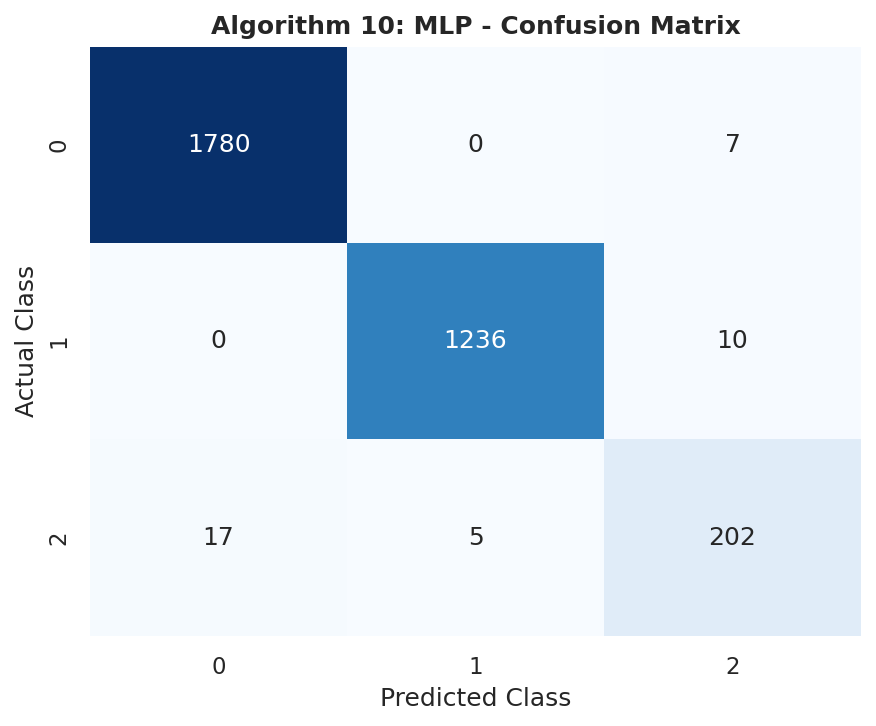

In [68]:

# ============================================================
# Algorithm 10: Confusion Matrix - MLP
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm_mlp = confusion_matrix(
    y_test_clf,
    preds_mlp_clf
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=[0, 1, 2],
    yticklabels=[0, 1, 2]
)

plt.title(
    'Algorithm 10: MLP - Confusion Matrix',
    fontsize=12,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()



### Interpretation — MLP Classifier

- **Overall performance:** Evaluate the test accuracy and weighted F1-score.
- **Precision and recall:** Examine how effectively the model predicts each class.
- **ROC-AUC:** Assess its ability to distinguish the three classes using One-vs-Rest.
- **Confusion matrix:** Identify correct predictions and misclassifications for classes 0, 1 and 2.
- **Conclusion:** Judge the model using the actual results and compare it with the other classifiers.



## Classification — Comparison of All 10 Algorithms

This table compares all ten classification algorithms using the same test dataset. The evaluation metrics are Accuracy, Weighted Precision, Weighted Recall, Weighted F1-score, and ROC-AUC using the One-vs-Rest (OvR) approach.


In [76]:

# ============================================================
# Classification: Comparison of All 10 Algorithms
# ============================================================

import pandas as pd
from IPython.display import display

comparison_clf = pd.DataFrame([
    {
        'Algorithm': '1. Logistic Regression',
        'Accuracy': acc_lr,
        'Precision': precision_lr,
        'Recall': recall_lr,
        'Weighted F1': f1_lr,
        'ROC-AUC': roc_lr
    },
    {
        'Algorithm': '2. K-Nearest Neighbors',
        'Accuracy': acc_knn,
        'Precision': precision_knn,
        'Recall': recall_knn,
        'Weighted F1': f1_knn,
        'ROC-AUC': roc_knn
    },
    {
        'Algorithm': '3. Gaussian Naive Bayes',
        'Accuracy': acc_nb,
        'Precision': precision_nb,
        'Recall': recall_nb,
        'Weighted F1': f1_nb,
        'ROC-AUC': roc_nb
    },
    {
        'Algorithm': '4. Decision Tree',
        'Accuracy': acc_dt_c,
        'Precision': precision_dt_c,
        'Recall': recall_dt_c,
        'Weighted F1': f1_dt_c,
        'ROC-AUC': roc_dt_c
    },
    {
        'Algorithm': '5. SVC',
        'Accuracy': acc_svc,
        'Precision': precision_svc,
        'Recall': recall_svc,
        'Weighted F1': f1_svc,
        'ROC-AUC': roc_svc
    },
    {
        'Algorithm': '6. Random Forest',
        'Accuracy': acc_rf,
        'Precision': precision_rf,
        'Recall': recall_rf,
        'Weighted F1': f1_rf,
        'ROC-AUC': roc_rf
    },
    {
        'Algorithm': '7. AdaBoost',
        'Accuracy': acc_ada,
        'Precision': precision_ada,
        'Recall': recall_ada,
        'Weighted F1': f1_ada,
        'ROC-AUC': roc_ada
    },
    {
        'Algorithm': '8. Gradient Boosting',
        'Accuracy': acc_gb,
        'Precision': precision_gb,
        'Recall': recall_gb,
        'Weighted F1': f1_gb,
        'ROC-AUC': roc_gb
    },
    {
        'Algorithm': '9. Bagging',
        'Accuracy': acc_bag,
        'Precision': precision_bag,
        'Recall': recall_bag,
        'Weighted F1': f1_bag,
        'ROC-AUC': roc_bag
    },
    {
        'Algorithm': '10. MLP Classifier',
        'Accuracy': acc_mlp,
        'Precision': precision_mlp,
        'Recall': recall_mlp,
        'Weighted F1': f1_mlp,
        'ROC-AUC': roc_mlp
    }
])

# Display all metrics to four decimal places
display(
    comparison_clf.style
    .format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'Weighted F1': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)


,Algorithm,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,1. Logistic Regression,0.8290,0.7797,0.8290,0.8020,0.9438
1,2. K-Nearest Neighbors,0.9527,0.9528,0.9527,0.9523,0.9942
2,3. Gaussian Naive Bayes,0.7347,0.7785,0.7347,0.7471,0.8973
3,4. Decision Tree,0.9113,0.9179,0.9113,0.8885,0.9865
4,5. SVC,0.9506,0.9486,0.9506,0.9484,0.9956
5,6. Random Forest,0.9917,0.9916,0.9917,0.9917,0.9999
6,7. AdaBoost,0.9085,0.9002,0.9085,0.9035,0.9602
7,8. Gradient Boosting,0.9675,0.9661,0.9675,0.9649,0.9983
8,9. Bagging,0.9975,0.9975,0.9975,0.9975,0.9999
9,10. MLP Classifier,0.9880,0.9879,0.9880,0.9880,0.9997



## Hyperparameter Tuning — Random Forest Classifier

GridSearchCV tests multiple Random Forest parameter combinations using cross-validation. The best configuration is evaluated on the same held-out test set used for the original classifiers.


In [77]:

# ============================================================
# Hyperparameter Tuning: Random Forest
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# Define the parameter combinations to test
# ------------------------------------------------------------

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# ------------------------------------------------------------
# Create GridSearchCV
# ------------------------------------------------------------

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ),
    param_grid=rf_param_grid,
    scoring='f1_weighted',
    cv=3,
    n_jobs=-1,
    verbose=1
)

# ------------------------------------------------------------
# Train using only the training data
# ------------------------------------------------------------

rf_grid.fit(
    X_train_clf_prep,
    y_train_clf
)

# Best model found by cross-validation
best_rf_clf = rf_grid.best_estimator_

print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross-Validation Weighted F1:")
print(f"{rf_grid.best_score_:.4f}")

# ------------------------------------------------------------
# Evaluate tuned model on the same test set
# ------------------------------------------------------------

preds_rf_tuned = best_rf_clf.predict(
    X_test_clf_prep
)

probs_rf_tuned = best_rf_clf.predict_proba(
    X_test_clf_prep
)

acc_rf_tuned = accuracy_score(
    y_test_clf,
    preds_rf_tuned
)

precision_rf_tuned = precision_score(
    y_test_clf,
    preds_rf_tuned,
    average='weighted',
    zero_division=0
)

recall_rf_tuned = recall_score(
    y_test_clf,
    preds_rf_tuned,
    average='weighted',
    zero_division=0
)

f1_rf_tuned = f1_score(
    y_test_clf,
    preds_rf_tuned,
    average='weighted',
    zero_division=0
)

roc_rf_tuned = roc_auc_score(
    y_test_clf,
    probs_rf_tuned,
    multi_class='ovr',
    average='weighted'
)

print("\n=== Tuned Random Forest Results ===")
print(f"Accuracy          : {acc_rf_tuned:.4f}")
print(f"Weighted Precision: {precision_rf_tuned:.4f}")
print(f"Weighted Recall   : {recall_rf_tuned:.4f}")
print(f"Weighted F1-score : {f1_rf_tuned:.4f}")
print(f"ROC-AUC (OvR)     : {roc_rf_tuned:.4f}")


Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation Weighted F1:
0.9869

=== Tuned Random Forest Results ===
Accuracy          : 0.9917
Weighted Precision: 0.9916
Weighted Recall   : 0.9917
Weighted F1-score : 0.9917
ROC-AUC (OvR)     : 0.9999


In [78]:

# ============================================================
# Original vs Tuned Random Forest
# ============================================================

rf_tuning_comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Weighted Precision',
        'Weighted Recall',
        'Weighted F1-score',
        'ROC-AUC'
    ],
    'Original': [
        acc_rf,
        precision_rf,
        recall_rf,
        f1_rf,
        roc_rf
    ],
    'Tuned': [
        acc_rf_tuned,
        precision_rf_tuned,
        recall_rf_tuned,
        f1_rf_tuned,
        roc_rf_tuned
    ]
})

rf_tuning_comparison['Change'] = (
    rf_tuning_comparison['Tuned']
    - rf_tuning_comparison['Original']
)

display(
    rf_tuning_comparison.style.format({
        'Original': '{:.4f}',
        'Tuned': '{:.4f}',
        'Change': '{:+.4f}'
    })
)


,Metric,Original,Tuned,Change
0,Accuracy,0.9917,0.9917,+0.0000
1,Weighted Precision,0.9916,0.9916,+0.0000
2,Weighted Recall,0.9917,0.9917,+0.0000
3,Weighted F1-score,0.9917,0.9917,+0.0000
4,ROC-AUC,0.9999,0.9999,+0.0000


Tuned Random Forest - Confusion Matrix
[[1778    0    9]
 [   0 1244    2]
 [   8    8  208]]


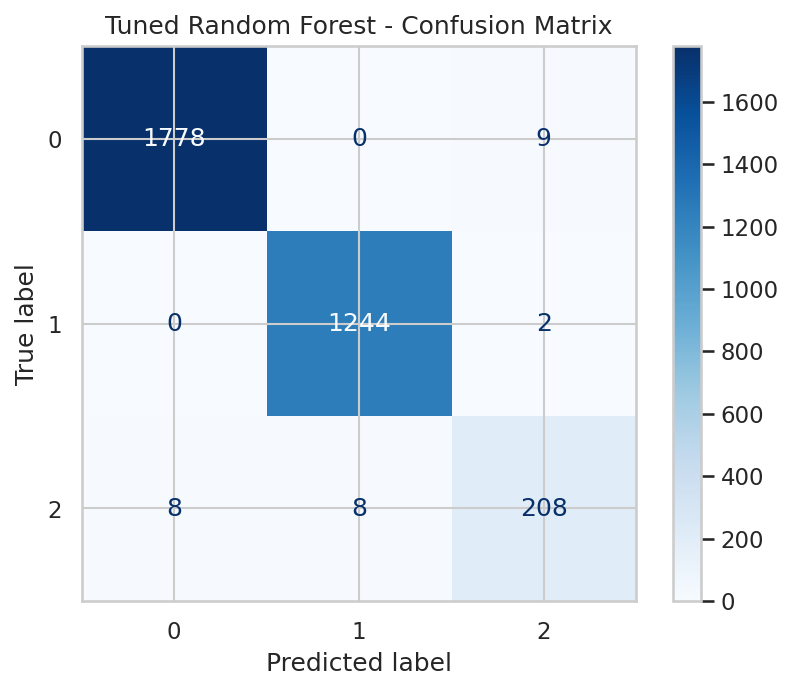

In [80]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predictions from the tuned Random Forest
preds_rf_tuned = best_rf_clf.predict(X_test_clf_prep)

# Generate confusion matrix
cm_rf_tuned = confusion_matrix(y_test_clf, preds_rf_tuned)

print("Tuned Random Forest - Confusion Matrix")
print(cm_rf_tuned)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_tuned,
    display_labels=best_rf_clf.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()


In [81]:

from sklearn.metrics import accuracy_score

print("Accuracy from tuned predictions:",
      accuracy_score(y_test_clf, preds_rf_tuned))

print("Stored tuned accuracy:", acc_rf_tuned)

print("Test samples:", len(y_test_clf))
print("Confusion matrix total:", cm_rf_tuned.sum())


Accuracy from tuned predictions: 0.9917101627264354
Stored tuned accuracy: 0.9917101627264354
Test samples: 3257
Confusion matrix total: 3257


## Final Model Selection — Classification

The classification task was evaluated using ten machine learning algorithms. Their performance was compared using Accuracy, Weighted Precision, Weighted Recall, Weighted F1-score, and ROC-AUC.

Random Forest achieved strong classification performance. After hyperparameter tuning using GridSearchCV, its Accuracy, Weighted F1-score, and ROC-AUC remained unchanged at 0.9917, 0.9917, and 0.9999, respectively. This indicates that tuning did not produce a measurable improvement over the original Random Forest model.

The tuned model's confusion matrix shows that most test samples were correctly classified. Class 2 had more misclassifications than Classes 0 and 1, indicating an opportunity for further improvement.

The final model should be selected by comparing the measured results of all ten classifiers, considering both overall performance and class-wise errors.

# FINAL INTERPRETATION AND ANALYSIS

## 1. Overall Project Interpretation

This project developed a machine learning framework for two smart agriculture tasks:

1. **Crop Yield Prediction** using regression.
2. **Agricultural Condition Classification** using multiclass classification.

The project followed a machine learning workflow involving dataset auditing, exploratory data analysis, preprocessing, feature engineering, model training, performance comparison, hyperparameter tuning, and diagnostic evaluation.

The regression dataset contains 19,689 records and 13 columns, while the classification dataset originally contains 16,411 records and 7 columns. No missing values were reported in the initial dataset inspection. The classification dataset contained 128 duplicate records, which were removed during preprocessing.

For the regression task, `Production` was excluded from the predictor variables because it could introduce target leakage into the crop-yield prediction task. Categorical features were encoded, and numerical features were scaled where appropriate. Preprocessing was fitted using training data to reduce the risk of data leakage.

For the classification task, the target variable `result` contains three classes: 0, 1, and 2. A stratified 80:20 train-test split was used to preserve class proportions between the training and testing sets.

The project evaluated multiple regression and classification algorithms to identify suitable predictive models based on their measured performance.

---

## 2. Regression Track Interpretation

Ten regression algorithms were evaluated using the held-out test dataset.

| Model | R² | RMSE | MAE |
|---|---:|---:|---:|
| Polynomial Regression | 0.9695 | 156.24 | 26.79 |
| Gradient Boosting | 0.9676 | 161.03 | 12.80 |
| Random Forest | 0.9621 | 174.20 | 12.44 |
| Decision Tree | 0.9471 | 205.90 | 15.27 |
| KNN Regressor | 0.8516 | 344.87 | 34.86 |
| Linear Regression | 0.8105 | 389.65 | 63.99 |
| Lasso Regression | 0.8102 | 389.95 | 60.90 |
| Ridge Regression | 0.8051 | 395.14 | 68.13 |
| SVR | 0.8020 | 398.31 | 87.52 |
| ElasticNet | 0.2474 | 776.55 | 151.80 |

### Regression observations

Polynomial Regression achieved the highest reported test-set R² of **0.9695**, indicating that the degree-2 polynomial transformation captured important nonlinear relationships in the available features.

Gradient Boosting achieved an R² of **0.9676**, demonstrating similarly strong predictive performance. Its RMSE was 161.03, while its MAE was 12.80.

Random Forest achieved an R² of **0.9621** and the lowest MAE among the three strongest models listed, at **12.44**. This indicates that its average absolute prediction error was low, even though Polynomial Regression achieved the highest R².

Decision Tree also performed strongly, with an R² of 0.9471, but its overall performance was below that of the leading models.

KNN Regressor achieved an R² of 0.8516. Linear Regression, Lasso, Ridge, and SVR produced R² values around 0.80–0.81, suggesting that their tested configurations did not capture the relationships in the dataset as effectively as the strongest nonlinear models.

ElasticNet produced the lowest reported R² of 0.2474 and the highest RMSE and MAE among the listed models. Its selected configuration was less suitable for this dataset than the other tested approaches.

Overall, Polynomial Regression achieved the highest reported R², while Random Forest achieved the lowest MAE among the three strongest models. Therefore, model selection depends on whether the main priority is explained variance or reducing average absolute prediction error.

---

## 3. Regression Hyperparameter Tuning Interpretation

RandomizedSearchCV was applied to Random Forest and Gradient Boosting using three-fold cross-validation.

### Random Forest

The selected configuration was:

- `n_estimators = 100`
- `max_depth = 12`
- `min_samples_split = 5`
- `min_samples_leaf = 4`

The best reported three-fold cross-validation R² was **0.8903**.

### Gradient Boosting

The selected configuration was:

- `n_estimators = 150`
- `learning_rate = 0.1`
- `max_depth = 2`
- `min_samples_split = 10`

The best reported three-fold cross-validation R² was **0.9306**.

Gradient Boosting achieved a higher reported cross-validation R² than Random Forest in these tuning experiments. This suggests that the selected Gradient Boosting configuration performed better under the cross-validation procedure used.

These cross-validation scores should be interpreted separately from the held-out test-set scores because they come from different evaluation procedures. The cross-validation results alone do not establish that one model will always generalize better than another.

---

## 4. Regression Diagnostic Interpretation

The predicted-versus-actual plot is used to examine how closely predicted crop-yield values follow the observed values. Points closer to the diagonal reference line indicate predictions closer to the actual observations.

The residual plot is used to examine prediction errors. Ideally, residuals should be distributed around zero without a strong systematic pattern. Visible patterns may indicate that the model has not captured some relationships in the data.

The Random Forest feature-importance analysis indicates which input features contributed to the model's predictions. These importance values represent predictive contribution within the fitted model and should not be interpreted as proof of causal relationships.

The regression target has a strongly skewed distribution and contains very large yield values. RMSE is particularly sensitive to large errors, while MAE provides a more direct measure of average absolute prediction error.

Consequently, the regression models should be compared using R², RMSE, and MAE together rather than relying on a single metric.

---

## 5. Classification Track Interpretation

Ten classification algorithms were evaluated using the prepared classification dataset:

1. Logistic Regression
2. K-Nearest Neighbors
3. Gaussian Naive Bayes
4. Decision Tree
5. Support Vector Classifier
6. Random Forest
7. AdaBoost
8. Gradient Boosting
9. Bagging Classifier with a Decision Tree base estimator
10. Multilayer Perceptron (MLP) Classifier

All ten models were evaluated using Accuracy, Weighted Precision, Weighted Recall, Weighted F1-score, and multiclass ROC-AUC using the one-vs-rest strategy.

The consolidated classification comparison table provides the quantitative basis for comparing these models. Accuracy measures the proportion of correct predictions, while weighted precision and recall summarize class-wise performance according to class support. Weighted F1-score combines precision and recall, and ROC-AUC measures class-separation performance using the one-vs-rest approach.

### Classification observations

Logistic Regression provides a linear classification baseline. Its performance indicates how effectively the classes can be separated using the decision boundaries learned by the model.

K-Nearest Neighbors classifies observations based on nearby training examples in the prepared feature space. Its performance depends on the distance relationships between samples and the choice of neighborhood size.

Gaussian Naive Bayes provides a probabilistic baseline based on conditional independence assumptions. Decision Tree learns nonlinear decision rules, while Support Vector Classifier attempts to separate classes using decision boundaries determined by the selected kernel and configuration.

Random Forest combines multiple decision trees to improve predictive robustness. AdaBoost and Gradient Boosting build ensembles sequentially, while Bagging combines predictions from multiple base estimators trained on sampled data. MLP learns nonlinear relationships using a neural-network architecture.

The measured values in the ten-algorithm comparison table should be used to identify the strongest classifier. A model with high accuracy and weighted F1-score provides strong overall classification performance, while ROC-AUC helps assess class-separation ability.

The final model should not be selected based on the algorithm name alone. Its actual test-set metrics, class-wise errors, and consistency of evaluation should guide the decision.

---

## 6. Classification Confusion-Matrix Interpretation

The confusion matrix for the tuned Random Forest model provides a class-by-class view of correct and incorrect predictions.

The matrix obtained was:

| Actual class | Predicted 0 | Predicted 1 | Predicted 2 |
|---|---:|---:|---:|
| Class 0 | 1778 | 0 | 9 |
| Class 1 | 0 | 1244 | 2 |
| Class 2 | 8 | 8 | 208 |

The diagonal entries represent correctly classified observations, while the off-diagonal entries represent misclassifications.

For Class 0, 1,778 observations were correctly classified, with 9 misclassified as Class 2. For Class 1, 1,244 observations were correctly classified, with 2 misclassified as Class 2. For Class 2, 208 observations were correctly classified, while 16 were assigned to other classes.

The matrix therefore shows strong classification performance for all three classes, although Class 2 accounts for the largest number of misclassifications. This makes class-specific evaluation important in addition to overall accuracy.

The confusion matrix complements the weighted metrics by showing where classification errors occur. However, the target labels 0, 1, and 2 should not be assigned agricultural meanings unless supported by the dataset documentation.

---

## 7. Classification Hyperparameter Tuning Interpretation

Random Forest was selected for a hyperparameter-tuning experiment using GridSearchCV with three-fold cross-validation. The search considered different values for the number of trees, maximum tree depth, and minimum samples required for a split.

The search used weighted F1-score as its optimization metric. This metric was selected to account for performance across the three classes while considering their support.

The original and tuned Random Forest models produced the following reported results:

| Metric | Original | Tuned |
|---|---:|---:|
| Accuracy | 0.9917 | 0.9917 |
| Weighted Precision | 0.9916 | 0.9916 |
| Weighted Recall | 0.9917 | 0.9917 |
| Weighted F1-score | 0.9917 | 0.9917 |
| ROC-AUC | 0.9999 | 0.9999 |

The displayed comparison shows no measurable change in these metrics after tuning, at the reported precision. Therefore, the tuning experiment did not demonstrate a performance improvement over the original Random Forest model.

This is a valid experimental finding. The tuned model retains strong measured performance, but the results do not justify claiming that hyperparameter tuning improved classification performance.

The final classifier should be selected by comparing all ten models and considering overall metrics, class-wise errors, and the intended application requirements.

---

## 8. Key Findings from the Regression and Classification Experiments

The main findings from the project are:

- The regression experiments show that nonlinear models performed strongly on the crop-yield prediction task.
- Polynomial Regression achieved the highest reported test-set R² of **0.9695**.
- Gradient Boosting achieved a test-set R² of **0.9676** and a reported tuning cross-validation R² of **0.9306**.
- Random Forest achieved the lowest MAE among the three strongest regression models listed, at **12.44**.
- Linear and regularized linear models performed below the strongest nonlinear and tree-based models in the reported regression results.
- Ten classification algorithms were evaluated using a common set of classification metrics.
- The tuned Random Forest confusion matrix shows that most test observations were classified correctly, with relatively more errors for Class 2.
- The Random Forest tuning comparison showed no measurable change in the reported classification metrics.
- Accuracy, weighted precision, weighted recall, weighted F1-score, ROC-AUC, and confusion matrices provide complementary information for evaluating classification models.
- The results demonstrate the importance of selecting models based on measured performance rather than assumptions about which algorithm should perform best.

Overall, the regression experiments identify Polynomial Regression as the highest-R² model in the reported test results, while the classification model should be selected using the actual ten-algorithm comparison table and the class-wise diagnostic results.



# CONCLUSION AND FUTURE SCOPE

## 1. Conclusion

This project demonstrates the application of machine learning to smart agriculture through two predictive tasks: crop yield prediction using regression and agricultural condition classification using multiclass classification.

For the **regression task**, ten algorithms were implemented and evaluated using a common held-out test set. Polynomial Regression achieved the highest reported test-set R² of **0.9695**, while Gradient Boosting achieved an R² of **0.9676** and Random Forest achieved an R² of **0.9621**. Random Forest also produced the lowest MAE among these three leading models, at **12.44**. These results demonstrate that nonlinear and tree-based approaches can capture useful relationships in the supplied agricultural dataset.

For the **classification task**, ten algorithms were implemented and compared: Logistic Regression, K-Nearest Neighbors, Gaussian Naive Bayes, Decision Tree, Support Vector Classifier, Random Forest, AdaBoost, Gradient Boosting, Bagging Classifier, and MLP Classifier. The models were evaluated using Accuracy, Weighted Precision, Weighted Recall, Weighted F1-score, and multiclass ROC-AUC using the one-vs-rest strategy.

The tuned Random Forest classifier achieved a reported accuracy of **0.9917**, a weighted F1-score of **0.9917**, and an ROC-AUC of **0.9999**. Its confusion matrix showed that most observations were classified correctly, although Class 2 accounted for more misclassifications than the other two classes. The hyperparameter-tuning comparison showed no measurable change in the reported metrics compared with the original Random Forest model.

The classification model should be selected by comparing the measured results of all ten algorithms, considering both overall performance and class-wise errors.

The project also demonstrates important machine learning practices, including exploratory data analysis, duplicate handling, categorical encoding, feature scaling, feature engineering, prevention of data leakage, train-test separation, model comparison, hyperparameter tuning, and diagnostic visualization.

The reported results represent performance on the supplied datasets and selected evaluation procedures. They do not establish causal relationships between agricultural variables and crop yield or between individual classification features and the target classes.

---

## 2. Limitations

1. The regression target has a highly skewed distribution and extreme values, which can influence RMSE and other evaluation metrics.
2. The datasets represent the observations available in the supplied files. Performance may differ across new agricultural regions, crops, seasons, and future years.
3. The classification target contains numerical classes `0`, `1`, and `2`. Their agricultural meanings should only be assigned when supported by reliable dataset documentation.
4. Feature importance indicates predictive contribution within a model and does not establish causation.
5. The classification results depend on the selected preprocessing procedure, train-test split, and model configurations.
6. The Random Forest tuning experiment did not produce a measurable improvement in the reported classification metrics.
7. The current results have not established that the models will maintain the same performance on independent datasets collected under different agricultural conditions.
8. Clustering analysis remains to be completed and evaluated before conclusions can be drawn about the groups discovered in the agricultural data.

---

## 3. Future Scope

The project can be extended in the following ways:

- Apply additional hyperparameter optimization to promising regression and classification models.
- Evaluate the selected models on additional unseen agricultural datasets to assess generalization.
- Investigate robust regression methods for handling highly skewed target distributions and extreme values.
- Explore additional domain-relevant engineered features that may improve prediction quality.
- Perform detailed class-wise precision, recall, and F1-score analysis for the classification task.
- Compare all ten classification algorithms using a consistent evaluation procedure and select the final model based on measured performance.
- Implement the clustering track using K-Means and Agglomerative Hierarchical Clustering.
- Use the Elbow method and a dendrogram to investigate suitable cluster configurations.
- Evaluate the clustering results using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Score.
- Visualize clusters using Principal Component Analysis (PCA) and explore t-SNE as an additional visualization technique.
- Investigate the relationship between discovered clusters and the known target classes after clustering, without using the target labels to form the clusters.
- Develop a simple application or dashboard through which users can provide agricultural inputs and receive model predictions.
- Explore integration with reliable real-time agricultural and environmental data sources.

---

## 4. Final Statement

Overall, the project demonstrates the potential of machine learning for predictive analysis of structured agricultural data. The regression experiments show strong performance from Polynomial Regression, Gradient Boosting, and Random Forest, while the classification experiments evaluate ten algorithms using a common set of performance metrics.

The tuned Random Forest classifier achieved strong reported classification performance, although the tuning experiment did not produce a measurable improvement over the original model. Final classifier selection should be supported by the complete ten-algorithm comparison and class-wise diagnostic results.

The next stage of the project is to complete the clustering analysis, evaluate the discovered groups using appropriate internal validation metrics, and visualize the results. Together, the regression, classification, and clustering tracks will provide a more comprehensive analysis of the supplied agricultural datasets.
